# Zero-shot cost-aware TCP: experiments for the revised paper (v2)

This notebook replaces the transfer part of `Zero-Shot Transfer.ipynb` (Cells 21–28) with one clean,
top-to-bottom pipeline and adds the experiments the paper needs.

**How to run.** Open a fresh kernel and run all cells in order. Step 0 sets the base folder to
`.../ML Test Prio/MEL-CI Papar`; every `.pkl` and dataset is looked up there first, then in `Dataset/`. Nothing from the old notebook's memory is needed. Outputs (CSV tables and one figure) go to
`zst_v2_outputs/`. Run time on a laptop: about 10 minutes with `USE_SVM = False`; about 30 minutes with the full
four-model ensemble (`USE_SVM = True`, the paper's model); Step 12 adds 15–30 minutes.

**Research firewall (no overlap with the ICST paper).** No LambdaRank, no Westermo data, no leave-one-project-out
*training*. EWMA appears only as a **baseline**, never blended into our score. Leave-one-target-out is used only to
estimate one scalar (the duration exponent) from the other target projects.

| Step | What it settles | Paper section |
|---|---|---|
| 2 (E0) | Rebuild + reconcile the transferred model | III (describe the 5 rank features actually transferred) |
| 3 (E1) | Protocol fixes: random ties, realised budgets, no sibling-job leakage; within-cycle AUC | III-E, IV, threats |
| 4 (E2) | Is the loss a prevalence problem? Odds equivalence, target sweep, 2×2 ablation | RQ1 |
| 5 (E3, E3b) | Theory: best exponent = (1 − κ)/b; in-domain vs transfer contrast | RQ2 |
| 6 (E4) | Exponent without target labels (leave-one-target-out) vs tuned α = 0.2 | RQ3 |
| 7 (E5) | Strong baselines incl. EWMA recency | RQ3 / RQ4 |
| 8 (E6) | Where the slope comes from (class weights, features, single models) | RQ2 |
| 9 (E7) | Early failure cycles of each project | RQ4 / discussion |
| 10 (E8) | APFD/APFDc and a two-stage order | RQ4 |
| 11 (E9) | Per-project Wilcoxon (Holm) + hierarchical bootstrap CIs | all RQs |
| 12 (E10) | All eligible RTPTorrent projects (optional, recommended) | external validity |
| 13 (E11) | Exponent regret on all projects; when transfer beats recency | RQ2, discussion |


In [1]:
# STEP 0 — Configuration. Run top to bottom in a fresh kernel.
from pathlib import Path
import os, time, warnings
warnings.filterwarnings("ignore")

# Base folder: every .pkl and every dataset is looked up here first.
BASE = Path("/Users/anis/My Research/Software Testing/ML Test Prio/MEL-CI Papar")

# If a dataset is not directly in BASE, these folders are searched next (in this order).
SEARCH_DIRS = [BASE, BASE / "Dataset", BASE / "dataset", BASE.parent / "Dataset", BASE.parent / "dataset"]

def find_file(*names):
    """Return the first existing file among `names`, searching SEARCH_DIRS in order."""
    for folder in SEARCH_DIRS:
        for name in names:
            if (folder / name).is_file():
                return folder / name
    return BASE / names[0]          # not found: Step 0 prints MISSING with the expected location

def find_dir(name):
    for folder in SEARCH_DIRS:
        if (folder / name).is_dir():
            return folder / name
    return BASE / name

PAINT_CSV = find_file("paintcontrol-additional-features copy.csv", "paintcontrol-additional-features.csv")
IOFROL_CSV = find_file("iofrol.csv")
RTP_DIR = find_dir("rtp-torrent")
RTP_TABLE = find_file("rtp_cycle_table.pkl")                       # written by Cell 21C
SELECTION_SCORED = find_file("rtp_zero_shot_scored.pkl")           # Cell 22E: the 1,800 selection cycles
CONFIRM_KEYS = find_file("cell27b_confirmatory_cycle_recall.csv")  # Cell 27B: the 2,111 confirmatory cycles
COMMITS_CSV = (RTP_DIR / "tr_all_built_commits.csv") if (RTP_DIR / "tr_all_built_commits.csv").is_file() \
    else find_file("tr_all_built_commits.csv")                     # job -> commit map shipped with RTPTorrent

OUT = BASE / "zst_v2_outputs"
OUT.mkdir(exist_ok=True)

USE_SVM = True          # True reproduces the paper's four-model ensemble (SVM scoring takes ~10-15 min)
IN_DOMAIN_SVM = False   # the in-domain check (Step 5b) retrains 10 times; SVM off keeps it to a few minutes
TIE_SEEDS = 10          # random tie-breaking repetitions for every strategy
N_EARLY = 50            # first failure cycles per project scored for the early-cycle analysis
HYBRID_ALPHA_PAPER = 0.2

print("BASE =", BASE, "| exists:", BASE.is_dir())
for name, path in [("Paint-Control", PAINT_CSV), ("IOF/ROL", IOFROL_CSV), ("RTP table", RTP_TABLE),
                   ("selection set", SELECTION_SCORED), ("confirmatory keys", CONFIRM_KEYS),
                   ("rtp-torrent folder", RTP_DIR), ("commit map (optional)", COMMITS_CSV)]:
    print(f"{name:22s} {'OK     ' if path.exists() else 'MISSING'} {path}")
print("Outputs go to", OUT)


BASE = /Users/anis/My Research/Software Testing/ML Test Prio/MEL-CI Papar | exists: True
Paint-Control          OK      /Users/anis/My Research/Software Testing/ML Test Prio/Dataset/paintcontrol-additional-features copy.csv
IOF/ROL                OK      /Users/anis/My Research/Software Testing/ML Test Prio/Dataset/iofrol.csv
RTP table              OK      /Users/anis/My Research/Software Testing/ML Test Prio/MEL-CI Papar/rtp_cycle_table.pkl
selection set          OK      /Users/anis/My Research/Software Testing/ML Test Prio/MEL-CI Papar/rtp_zero_shot_scored.pkl
confirmatory keys      OK      /Users/anis/My Research/Software Testing/ML Test Prio/MEL-CI Papar/cell27b_confirmatory_cycle_recall.csv
rtp-torrent folder     OK      /Users/anis/My Research/Software Testing/ML Test Prio/Dataset/rtp-torrent
commit map (optional)  OK      /Users/anis/My Research/Software Testing/ML Test Prio/Dataset/rtp-torrent/tr_all_built_commits.csv
Outputs go to /Users/anis/My Research/Software Testing/ML Te

## Step 1 — Core functions
Feature definitions are copied from Cells 6 and 22E so the numbers stay comparable. The evaluator is vectorised:
one call scores every cycle at once, so 10 tie-breaking seeds cost seconds.

* `recall(score, cost="obs")` orders by the score, then executes the prefix whose **realised** duration fits the budget
  (`cost="est"` reproduces the draft, which counts estimated durations).
* `conditional_slope` fits failure ~ b·logit(p) + κ·log(d) **within cycles** (cycle intercepts drop out).

In [2]:
# STEP 1 — Core functions (data, features, models, evaluation). Nothing runs here; it only defines functions.
import os, time, json, warnings
import numpy as np
import pandas as pd
from scipy.special import expit, logit
from scipy.stats import wilcoxon, spearmanr
from scipy.optimize import minimize
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
warnings.filterwarnings("ignore")

BUDGETS = [0.10, 0.20, 0.30, 0.50]
FEATURES = ["rank_failure_rate", "rank_execution_count", "rank_previous_duration",
            "previous_verdict_filled", "has_failed_before"]
SEED = 2026
EPS = 1e-6

# --------------------------------------------------------------------------------------------
# 1. Industrial (ABB) source data: Paint-Control and IOF/ROL  (same steps as Cells 3-6)
# --------------------------------------------------------------------------------------------
def _read_csv_flexible(path):
    with open(path, "r", encoding="utf-8-sig", errors="replace") as f:
        header = f.readline()
    sep = ";" if header.count(";") > header.count(",") else ","
    return pd.read_csv(path, sep=sep, low_memory=False)

def load_abb(paint_path, iofrol_path):
    parts = []
    for path, name in [(paint_path, "Paint-Control"), (iofrol_path, "IOF-ROL")]:
        raw = _read_csv_flexible(path)
        df = pd.DataFrame({
            "test_id": raw["Name"].astype(str).str.strip(),
            "cycle_id": pd.to_numeric(raw["Cycle"], errors="coerce"),
            "failure": raw["Verdict"].astype(str).str.strip().str.lower()
                          .map({"1": 1, "1.0": 1, "0": 0, "0.0": 0}).astype(int),
            "duration": pd.to_numeric(raw["Duration"], errors="coerce"),
        })
        df = df[df["cycle_id"].notna()].copy()
        df["cycle_id"] = df["cycle_id"].astype(int)
        df.loc[df["duration"] < 0, "duration"] = np.nan
        tc = (df.groupby(["cycle_id", "test_id"], as_index=False)
                .agg(failure=("failure", "max"), executions_in_cycle=("failure", "size"),
                     failures_in_cycle=("failure", "sum"), observed_duration_mean=("duration", "mean")))
        order = {c: i for i, c in enumerate(sorted(tc["cycle_id"].unique()), start=1)}
        tc["cycle_position"] = tc["cycle_id"].map(order).astype(int)
        tc["project"] = name
        parts.append(tc)
    return pd.concat(parts, ignore_index=True)

def add_history_features(tc):
    """Past-only features used by the transfer model (identical definitions to Cell 6)."""
    df = tc.sort_values(["project", "test_id", "cycle_position"], kind="mergesort").reset_index(drop=True)
    g = df.groupby(["project", "test_id"], sort=False)
    df["previous_verdict"] = g["failure"].shift(1)
    df["previous_duration"] = g["observed_duration_mean"].shift(1)
    df["historical_execution_count"] = (g["executions_in_cycle"].cumsum() - df["executions_in_cycle"]).astype(float)
    df["historical_failure_count"] = (g["failures_in_cycle"].cumsum() - df["failures_in_cycle"]).astype(float)
    df["historical_failure_percentage"] = np.where(
        df["historical_execution_count"] > 0,
        df["historical_failure_count"] / df["historical_execution_count"].replace(0, np.nan), np.nan)
    return df.sort_values(["project", "cycle_position", "test_id"], kind="mergesort").reset_index(drop=True)

def add_scale_free_features(t):
    """Within-cycle percentile ranks (Cell 22E). Ranks are computed per (project, cycle)."""
    t = t.copy()
    g = t.groupby(["project", "cycle_position"], sort=False)
    t["rank_failure_rate"] = g["historical_failure_percentage"].rank(pct=True)
    t["rank_execution_count"] = g["historical_execution_count"].rank(pct=True)
    t["rank_previous_duration"] = g["previous_duration"].rank(pct=True)
    t["previous_verdict_filled"] = t["previous_verdict"]
    t["has_failed_before"] = (t["historical_failure_count"] > 0).astype(float)
    for c in FEATURES:
        t[c] = t[c].fillna(-1.0)
    return t

# --------------------------------------------------------------------------------------------
# 2. RTPTorrent target data
# --------------------------------------------------------------------------------------------
def rtp_history_table(rtp_cycles, build_level=False, sibling_gap=5, job_commits=None):
    """Turn the Cell 21C table into the feature frame. With build_level=True, a job's history
    excludes sibling jobs of the same Travis build (consecutive job ids within `sibling_gap`
    and, when known, the same commit), because those jobs run in parallel."""
    r = rtp_cycles[["project", "travisJobId", "cycleposition", "testid", "actualfailure",
                    "observedduration", "estimatedduration"]].rename(columns={
        "cycleposition": "cycle_position", "testid": "test_id", "actualfailure": "failure",
        "observedduration": "observed_duration_mean", "estimatedduration": "estimated_duration"})
    jobs = r[["project", "travisJobId", "cycle_position"]].drop_duplicates().sort_values(["project", "travisJobId"])
    if job_commits is not None:
        jobs = jobs.merge(job_commits, on=["project", "travisJobId"], how="left")
    else:
        jobs["commit"] = np.nan
    gap = jobs.groupby("project")["travisJobId"].diff()
    prev_commit = jobs.groupby("project")["commit"].shift(1)
    same = (gap <= sibling_gap) & (jobs["commit"].isna() | prev_commit.isna() | (jobs["commit"] == prev_commit))
    jobs["build"] = (~same).groupby(jobs["project"]).cumsum()
    r = r.merge(jobs[["project", "travisJobId", "build"]], on=["project", "travisJobId"], how="left")
    r["executions_in_cycle"] = 1
    r["failures_in_cycle"] = r["failure"]
    df = r.sort_values(["project", "test_id", "cycle_position"], kind="mergesort").reset_index(drop=True)
    g = df.groupby(["project", "test_id"], sort=False)
    if not build_level:
        df["previous_verdict"] = g["failure"].shift(1)
        df["previous_duration"] = g["observed_duration_mean"].shift(1)
        df["historical_execution_count"] = g.cumcount().astype(float)
        df["historical_failure_count"] = (g["failure"].cumsum() - df["failure"]).astype(float)
    else:
        # history = everything in earlier builds; sibling jobs of the same build are invisible
        key = ["project", "test_id", "build"]
        first = df.groupby(key, sort=False).cumcount() == 0
        cnt = g.cumcount().astype(float)
        cf = (g["failure"].cumsum() - df["failure"]).astype(float)
        pv = g["failure"].shift(1); pdur = g["observed_duration_mean"].shift(1)
        for col, val in [("historical_execution_count", cnt), ("historical_failure_count", cf),
                         ("previous_verdict", pv), ("previous_duration", pdur)]:
            df[col] = val.where(first)
            df[col] = df.groupby(key, sort=False)[col].transform("first")
    df["historical_failure_percentage"] = np.where(
        df["historical_execution_count"] > 0,
        df["historical_failure_count"] / df["historical_execution_count"].replace(0, np.nan), np.nan)
    # EWMA recency baseline (lambda = 0.2), same visibility rule as the other features
    y = df["failure"].to_numpy(float)
    keyarr = (df["project"].astype(str) + "|" + df["test_id"].astype(str)).to_numpy()
    start = np.r_[True, keyarr[1:] != keyarr[:-1]]
    e = np.zeros(len(y)); prev = 0.0
    for i in range(len(y)):
        if start[i]:
            prev = 0.0
        e[i] = prev
        prev = 0.8 * prev + 0.2 * y[i]
    df["ewma"] = e
    if build_level:
        df["ewma"] = df.groupby(["project", "test_id", "build"], sort=False)["ewma"].transform("first")
    # duration estimate for scheduling: mean of earlier observed durations (Cell 21C rule)
    if build_level:
        prior_sum = (g["observed_duration_mean"].cumsum() - df["observed_duration_mean"])
        est = (prior_sum / df.groupby(["project", "test_id"], sort=False).cumcount().replace(0, np.nan))
        est = est.where(df.groupby(["project", "test_id", "build"], sort=False).cumcount() == 0)
        est = est.groupby([df["project"], df["test_id"], df["build"]], sort=False).transform("first")
        fallback = df.loc[df["observed_duration_mean"] > 0].groupby("project")["observed_duration_mean"].median()
        df["estimated_duration"] = est.fillna(df["project"].map(fallback)).clip(lower=1e-3)
    return df.sort_values(["project", "cycle_position", "test_id"], kind="mergesort").reset_index(drop=True)

# --------------------------------------------------------------------------------------------
# 3. Models (the Cell 22E transfer ensemble, plus switches for the ablations)
# --------------------------------------------------------------------------------------------
def fit_transfer_models(train, class_weight=True, features=FEATURES, use_svm=True,
                        max_svm_rows=40000, seed=SEED, which=("gradient_boosting", "random_forest", "knn", "svm")):
    X = train[features].to_numpy(float); y = train["failure"].astype(int).to_numpy()
    models = {}
    if "gradient_boosting" in which:
        gb = GradientBoostingClassifier(learning_rate=0.1, max_depth=2, min_samples_leaf=1,
                                        n_estimators=100, random_state=seed)
        gb.fit(X, y, sample_weight=compute_sample_weight("balanced", y) if class_weight else None)
        models["gradient_boosting"] = gb
    if "random_forest" in which:
        rf = RandomForestClassifier(n_estimators=200, max_depth=12, max_features="sqrt", min_samples_leaf=3,
                                    class_weight="balanced" if class_weight else None, n_jobs=-1, random_state=seed)
        models["random_forest"] = rf.fit(X, y)
    if "knn" in which:
        models["knn"] = make_pipeline(StandardScaler(), KNeighborsClassifier(
            n_neighbors=51, weights="distance", p=2, n_jobs=-1)).fit(X, y)
    if "svm" in which and use_svm:
        idx = np.arange(len(X))
        if len(idx) > max_svm_rows:
            idx = np.random.default_rng(seed).choice(idx, max_svm_rows, replace=False)
        models["svm"] = make_pipeline(StandardScaler(), SVC(
            C=0.5, kernel="rbf", gamma="scale", probability=True,
            class_weight="balanced" if class_weight else None, random_state=seed)).fit(X[idx], y[idx])
    if "logistic" in which:
        models["logistic"] = make_pipeline(StandardScaler(), LogisticRegression(
            max_iter=2000, class_weight="balanced" if class_weight else None)).fit(X, y)
    return models

def score_models(models, frame, features=FEATURES, chunk=200000):
    X = frame[features].to_numpy(float)
    out = {}
    for name, m in models.items():
        out[name] = np.concatenate([m.predict_proba(X[i:i + chunk])[:, 1] for i in range(0, len(X), chunk)])
    return pd.DataFrame(out, index=frame.index)

# --------------------------------------------------------------------------------------------
# 4. Fast, vectorised evaluation (all cycles at once)
# --------------------------------------------------------------------------------------------
class CycleSet:
    """Holds one evaluation frame sorted by cycle. `score` arrays must follow this order."""
    def __init__(self, frame, label="failure", est="estimated_duration", obs="observed_duration_mean"):
        f = frame.sort_values(["project", "cycle_position"], kind="mergesort").reset_index(drop=True)
        self.frame = f
        self.cyc = f.groupby(["project", "cycle_position"], sort=False).ngroup().to_numpy()
        self.n_cyc = int(self.cyc.max()) + 1
        self.y = f[label].astype(int).to_numpy()
        self.est = f[est].astype(float).clip(lower=1e-6).to_numpy()
        o = f[obs].astype(float).to_numpy()
        self.obs = np.where(np.isfinite(o), o, self.est).clip(min=0.0)
        self.cyc_project = f.groupby(self.cyc)["project"].first().to_numpy()
        self.cyc_position = f.groupby(self.cyc)["cycle_position"].first().to_numpy()
        self.n_fail = np.bincount(self.cyc, weights=self.y, minlength=self.n_cyc)
        self.size = np.bincount(self.cyc, minlength=self.n_cyc)
        self.tid = pd.factorize(f["test_id"].astype(str), sort=True)[0].astype(float)

    def _order(self, score, seed, tie="random"):
        # tie="random": fresh random tie-break per seed; tie="id": ascending test identifier (the draft's rule)
        noise = self.tid if tie == "id" else np.random.default_rng(seed).random(len(self.y))
        return np.lexsort((noise, -np.asarray(score, float), self.cyc))

    def _within(self, values_sorted, cyc_sorted):
        cum = np.cumsum(values_sorted)
        starts = np.r_[0, np.flatnonzero(np.diff(cyc_sorted)) + 1]
        lengths = np.diff(np.r_[starts, len(values_sorted)])
        return cum - np.repeat(cum[starts] - values_sorted[starts], lengths)

    def recall(self, score, cost="obs", seeds=10, budgets=BUDGETS, tie="random"):
        """Budgeted recall per cycle (rows: cycles, cols: budgets), averaged over random
        tie-breaking seeds. cost='obs': the budget and the executed prefix use the realised
        durations (the schedule only sees estimates through the score). cost='est': both use
        estimated durations (the protocol of the current draft)."""
        c_all = self.obs if cost == "obs" else self.est
        total = np.bincount(self.cyc, weights=c_all, minlength=self.n_cyc)
        out = np.zeros((self.n_cyc, len(budgets)))
        seeds = 1 if tie == "id" else seeds
        for s in range(seeds):
            o = self._order(score, 1000 + s, tie)
            cc, yy, cost_s = self.cyc[o], self.y[o], c_all[o]
            cum = self._within(cost_s, cc)
            for j, b in enumerate(budgets):
                inside = cum <= b * total[cc] + 1e-12
                out[:, j] += np.bincount(cc, weights=yy * inside, minlength=self.n_cyc)
        with np.errstate(invalid="ignore", divide="ignore"):
            return out / seeds / self.n_fail[:, None]

    def order_metrics(self, score, seeds=10, tie="random"):
        """APFD and APFDc (realised durations) per cycle, averaged over tie-breaking seeds."""
        apfd = np.zeros(self.n_cyc); apfdc = np.zeros(self.n_cyc)
        total = np.bincount(self.cyc, weights=self.obs, minlength=self.n_cyc)
        total = np.where(total > 0, total, 1.0)
        seeds = 1 if tie == "id" else seeds
        for s in range(seeds):
            o = self._order(score, 1000 + s, tie)
            cc, yy, co = self.cyc[o], self.y[o], self.obs[o]
            pos = self._within(np.ones(len(cc)), cc)
            cum = self._within(co, cc)
            tail = total[cc] - cum + co
            n, m = self.size[cc], self.n_fail[cc]
            apfd += np.bincount(cc, weights=yy * pos, minlength=self.n_cyc)
            apfdc += np.bincount(cc, weights=yy * (tail - 0.5 * co), minlength=self.n_cyc)
        apfd = 1 - apfd / seeds / (self.size * self.n_fail) + 1 / (2 * self.size)
        apfdc = apfdc / seeds / (total * self.n_fail)
        return apfd, apfdc

    def within_cycle_auc(self, score):
        """Mean within-cycle ROC-AUC (cycles with at least one pass and one failure)."""
        f = pd.DataFrame({"c": self.cyc, "s": np.asarray(score, float), "y": self.y})
        f["r"] = f.groupby("c")["s"].rank(method="average")
        npos = self.n_fail; nneg = self.size - self.n_fail
        sum_r = np.bincount(self.cyc, weights=f["r"].to_numpy() * self.y, minlength=self.n_cyc)
        with np.errstate(invalid="ignore", divide="ignore"):
            auc = (sum_r - npos * (npos + 1) / 2) / (npos * nneg)
        auc[(npos == 0) | (nneg == 0)] = np.nan
        return auc

    def by_project(self, per_cycle):
        """Project means (rows: projects). Equal project weight = the mean of these rows."""
        df = pd.DataFrame(per_cycle if np.ndim(per_cycle) > 1 else per_cycle[:, None])
        df["project"] = self.cyc_project
        return df[df.notna().all(axis=1)].groupby("project").mean()

    def paper_prior_target(self):
        """Per-cycle prevalence estimate exactly as coded in Cell 25 (pooled earlier failures over
        pooled earlier executions of the cycle's tests, clipped to [1e-4, 0.5])."""
        f = self.frame
        F = np.bincount(self.cyc, weights=f["historical_failure_count"].fillna(0).to_numpy(), minlength=self.n_cyc)
        n = np.bincount(self.cyc, weights=f["historical_execution_count"].fillna(0).to_numpy(), minlength=self.n_cyc)
        return np.clip(F / np.maximum(n, 1), 1e-4, 0.5)

    def per_cycle_shift(self, p, target):
        """Logit shift per cycle so that the cycle mean equals `target` (scalar or per cycle)."""
        x = logit(np.clip(p, EPS, 1 - EPS))
        t = np.broadcast_to(np.asarray(target, float), (self.n_cyc,)) if np.ndim(target) == 0 else np.asarray(target)
        lo = np.full(self.n_cyc, -40.0); hi = np.full(self.n_cyc, 40.0)
        for _ in range(60):
            mid = (lo + hi) / 2
            m = np.bincount(self.cyc, weights=expit(x + mid[self.cyc]), minlength=self.n_cyc) / self.size
            lo = np.where(m < t, mid, lo); hi = np.where(m < t, hi, mid)
        return expit(x + ((lo + hi) / 2)[self.cyc])

    def conditional_slope(self, logit_score, mask_cycles=None, with_duration=True, duration=None):
        """Within-cycle (conditional, Breslow) logistic fit of failure on the model logit and,
        optionally, log duration. Returns (b, kappa). The optimal exponent is (1 - kappa) / b."""
        keep = np.ones(len(self.y), bool) if mask_cycles is None else np.isin(self.cyc, mask_cycles)
        xs = np.asarray(logit_score, float)[keep]; ys = self.y[keep]
        ci = np.unique(self.cyc[keep], return_inverse=True)[1]
        X = np.c_[xs, np.log(np.asarray(duration if duration is not None else self.est)[keep])] if with_duration else xs[:, None]
        m = np.bincount(ci, weights=ys)
        def nll_grad(th):
            z = X @ th
            mx = np.full(ci.max() + 1, -np.inf); np.maximum.at(mx, ci, z)
            w = np.exp(z - mx[ci]); S = np.bincount(ci, weights=w)
            lse = np.log(S) + mx
            pr = w / S[ci]
            nll = -((ys * z).sum() - (m * lse).sum())
            grad = -((ys[:, None] * X).sum(0) - np.array([np.bincount(ci, weights=pr * X[:, k]) @ m for k in range(X.shape[1])]))
            return nll, grad
        th = minimize(nll_grad, np.full(X.shape[1], 0.5), jac=True, method="BFGS").x
        return (th[0], th[1]) if with_duration else (th[0], 0.0)

def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); adj = np.empty_like(p); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (len(p) - rank) * p[i])); adj[i] = run
    return adj

def paired(a, b):
    """Wilcoxon on per-cycle differences (zeros dropped) and rank-biserial effect size."""
    d = np.asarray(a) - np.asarray(b); d = d[np.isfinite(d)]; nz = d[d != 0]
    if len(nz) == 0:
        return dict(mean_diff=0.0, improved=0, worse=0, p=1.0, rb=0.0)
    r = pd.Series(np.abs(nz)).rank().to_numpy()
    return dict(mean_diff=d.mean(), improved=int((d > 0).sum()), worse=int((d < 0).sum()),
                p=float(wilcoxon(nz).pvalue), rb=float((r[nz > 0].sum() - r[nz < 0].sum()) / r.sum()))

def equal_weight(C, per_cycle):
    """Mean over projects of the project means (each project counts once), in percent."""
    return C.by_project(per_cycle).mean() * 100

def cycle_weight(per_cycle):
    return np.nanmean(per_cycle, axis=0) * 100

def hierarchical_bootstrap(diff_per_cycle, cyc_project, n_boot=2000, seed=7):
    """95% CI of the equal-project-weight mean difference: resample projects, then cycles."""
    rng = np.random.default_rng(seed)
    groups = [diff_per_cycle[(cyc_project == p) & np.isfinite(diff_per_cycle)] for p in np.unique(cyc_project)]
    stats = np.empty(n_boot)
    for i in range(n_boot):
        pick = rng.integers(0, len(groups), len(groups))
        stats[i] = np.mean([rng.choice(groups[k], len(groups[k])).mean() for k in pick])
    point = np.mean([g.mean() for g in groups])
    return point, np.percentile(stats, 2.5), np.percentile(stats, 97.5)


## Step 2 (E0) — Rebuild and reconcile the transferred model
**Why.** The draft describes an 11-feature tuned ensemble (Table III), but Cell 22E transfers a different model:
five within-cycle rank features (`rank_failure_rate`, `rank_execution_count`, `rank_previous_duration`,
`previous_verdict`, `has_failed_before`) with fixed hyperparameters. Reviewers who open the replication package will
see this, so Section III must describe the transferred model as it is.

**Look for.** Features and gradient-boosting probabilities match the saved run exactly. Random forest and k-NN may
differ slightly across scikit-learn versions (k-NN has many exact distance ties).

In [3]:
# STEP 2 (E0) — Rebuild the transfer pipeline in one place and check it reproduces the saved run.
# Why: the paper must describe the model that was actually transferred. Cell 22E trains on FIVE
# within-cycle rank features (not the 11 features of Table III), so the paper text has to change.
t0 = time.time()

# 2a. Source: ABB industrial data -> the five scale-free features of Cell 22E
abb = add_history_features(load_abb(PAINT_CSV, IOFROL_CSV))
train = add_scale_free_features(abb)
print(f"Source rows {len(train):,} | failure prevalence {train['failure'].mean():.2%}")
models = fit_transfer_models(train, use_svm=USE_SVM)
print("Models:", list(models), f"({time.time() - t0:.0f}s)")

# 2b. Target: RTPTorrent. Job->commit map identifies parallel sibling jobs of one Travis build.
rtp_cycles = pd.read_pickle(RTP_TABLE)

def load_job_commits(rtp_cycles, cache=OUT / "job_commits.csv"):
    if cache.exists():
        return pd.read_csv(cache)
    if not COMMITS_CSV.exists():
        print("tr_all_built_commits.csv not found: siblings are detected from job-id gaps only.")
        return None
    jobs = rtp_cycles[["project", "travisJobId"]].drop_duplicates()
    wanted = set(jobs["travisJobId"])
    parts = []
    for chunk in pd.read_csv(COMMITS_CSV, chunksize=1_000_000):
        chunk.columns = ["travisJobId", "commit"]
        parts.append(chunk[chunk["travisJobId"].isin(wanted)])
    jc = jobs.merge(pd.concat(parts), on="travisJobId", how="inner")
    jc = jc.sort_values(["project", "travisJobId", "commit"]).drop_duplicates(["project", "travisJobId"])
    jc["commit"] = pd.factorize(jc["commit"])[0]
    jc[["project", "travisJobId", "commit"]].to_csv(cache, index=False)
    return jc[["project", "travisJobId", "commit"]]

job_commits = load_job_commits(rtp_cycles)

# 2c. Which cycles to score: the paper's selection (1,800) and confirmatory (2,111) cycles, plus the
#     first N_EARLY failure cycles of every project (needed for Steps 5 and 8).
sel_keys = pd.read_pickle(SELECTION_SCORED)[["project", "cycle_position"]].drop_duplicates().assign(set_selection=True)
if CONFIRM_KEYS.exists():
    conf_keys = pd.read_csv(CONFIRM_KEYS)[["project", "cycle_position"]].drop_duplicates().assign(set_confirm=True)
else:
    raise FileNotFoundError("cell27b_confirmatory_cycle_recall.csv is needed to recover the confirmatory cycles.")
print(f"selection cycles {len(sel_keys):,} | confirmatory cycles {len(conf_keys):,}")

def score_level(build_level):
    H = rtp_history_table(rtp_cycles, build_level=build_level, job_commits=job_commits)
    fc = (H.groupby(["project", "cycle_position"], sort=False)["failure"].max()
            .loc[lambda s: s == 1].reset_index()[["project", "cycle_position"]])
    early = fc.sort_values(["project", "cycle_position"]).groupby("project").head(N_EARLY).assign(set_early=True)
    keys = (fc.merge(sel_keys, how="left", on=["project", "cycle_position"])
              .merge(conf_keys, how="left", on=["project", "cycle_position"])
              .merge(early, how="left", on=["project", "cycle_position"]))
    for c in ["set_selection", "set_confirm", "set_early"]:
        keys[c] = keys[c].astype("boolean").fillna(False).astype(bool)
    keys = keys[keys[["set_selection", "set_confirm", "set_early"]].any(axis=1)]
    sub = add_scale_free_features(H.merge(keys, on=["project", "cycle_position"]))
    P = score_models(models, sub)
    sub = pd.concat([sub, P.add_prefix("probability_")], axis=1)
    sub["p_ens"] = P.mean(axis=1).to_numpy()
    return sub, len(fc)

scored = {}
for level in ["job", "build"]:
    scored[level], n_fc = score_level(level == "build")
    scored[level].to_pickle(OUT / f"scored_{level}.pkl")
    print(f"{level}-level history: {len(scored[level]):,} rows scored | {n_fc:,} failure cycles in total "
          f"({time.time() - t0:.0f}s)")

# 2d. Reconciliation with the saved Cell 22E run (job-level history = the draft's protocol)
saved = pd.read_pickle(SELECTION_SCORED)
chk = scored["job"].merge(saved[["project", "cycle_position", "test_id"] + FEATURES +
                                [c for c in saved.columns if c.startswith("probability_")]],
                          on=["project", "cycle_position", "test_id"], suffixes=("", "_saved"))
rows = [{"item": f, "max_abs_diff": float(np.abs(chk[f] - chk[f + "_saved"]).max())} for f in FEATURES]
for m in models:
    rows.append({"item": f"probability_{m}", "max_abs_diff": float(np.abs(chk[f"probability_{m}"] - chk[f"probability_{m}_saved"]).max())})
if len(models) == 4 and "probability_equal_voting_4" in chk.columns:
    rows.append({"item": "equal-vote ensemble", "max_abs_diff": float(np.abs(chk["p_ens"] - chk["probability_equal_voting_4"]).max())})
recon = pd.DataFrame(rows)
display(recon)
print(f"Matched rows: {len(chk):,} of {len(saved):,}. Features and gradient boosting should match exactly;")
print("random forest and k-NN can differ slightly if scikit-learn or row order differ (k-NN has many distance ties).")
recon.to_csv(OUT / "E0_reconciliation.csv", index=False)


Source rows 49,924 | failure prevalence 21.09%
Models: ['gradient_boosting', 'random_forest', 'knn', 'svm'] (269s)
selection cycles 1,800 | confirmatory cycles 2,111
job-level history: 280,733 rows scored | 8,871 failure cycles in total (548s)
build-level history: 280,733 rows scored | 8,871 failure cycles in total (830s)


,item,max_abs_diff
0,rank_failure_rate,0.000000e+00
1,rank_execution_count,0.000000e+00
2,rank_previous_duration,0.000000e+00
3,previous_verdict_filled,0.000000e+00
4,has_failed_before,0.000000e+00
5,probability_gradient_boosting,0.000000e+00
6,probability_random_forest,4.440892e-16
7,probability_knn,0.000000e+00
8,probability_svm,0.000000e+00
9,equal-vote ensemble,2.220446e-16


Matched rows: 118,756 of 118,756. Features and gradient boosting should match exactly;
random forest and k-NN can differ slightly if scikit-learn or row order differ (k-NN has many distance ties).


## Step 3 (E1) — Protocol fixes
**Why.** Three things a careful reviewer (RTPTorrent's own authors sit on the MSR PC) will ask about:
1. ties broken by test id (most tests tie under HistoricalFailure),
2. budgets counted in *estimated* durations (your threats section already admits this),
3. **sibling-job leakage**: Travis runs the jobs of one build in parallel, but the job-ordered history lets a job see
   its siblings' verdicts. The sibling table shows how often a failing test's "previous run" is a parallel sibling.

**Look for.** How much each fix moves each strategy (first table), the sibling shares, and within-cycle AUC.
Use the corrected protocol (last column) for every later step and say so in Section III.

**Paper.** Replace "ranking survives (ROC-AUC 0.91/0.89)" with the within-cycle AUC table: pooled AUC rewards
separating tests across cycles, which no prioritiser needs.

In [4]:
# STEP 3 (E1) — Fix the evaluation protocol and show how much each fix moves the numbers.
# Three changes, each a reviewer request we can pre-empt:
#   (i)  random tie-breaking averaged over TIE_SEEDS (the draft breaks ties by test id; most tests tie
#        under HistoricalFailure because their failure rate is 0),
#   (ii) realised-duration budgets: the order uses estimated durations, but the budget and the executed
#        prefix use the real durations (the draft counts estimated durations, see its threats section),
#   (iii) build-level history: Travis jobs of one build run in parallel, so a job must not see the verdicts
#        of its sibling jobs (job-level history leaks them; see the sibling-share table below).
# All tables use EQUAL PROJECT WEIGHT (mean of project means); cycle-weighted values are saved too.

def strategies_paper(C):
    f = C.frame
    p = f["p_ens"].clip(EPS, 1 - EPS).to_numpy()
    p_prior = C.per_cycle_shift(p, C.paper_prior_target())
    return {
        "EnsembleRisk": p,
        "RiskPerTime (raw) p/d": p / C.est,
        "RiskPerTime (prior) p~/d": p_prior / C.est,
        f"Hybrid p~ d^-{HYBRID_ALPHA_PAPER}": p_prior * C.est ** -HYBRID_ALPHA_PAPER,
        "HistoricalFailure": f["historical_failure_percentage"].fillna(0).to_numpy(),
        "ShortestFirst": -C.est,
    }

protocols = [("draft: job history, est. budget, id ties", "job", "est", "id"),
             ("+ random ties", "job", "est", "random"),
             ("+ realised budget", "job", "obs", "random"),
             ("+ build-level history (corrected)", "build", "obs", "random")]
rows = []
for label, level, cost, tie in protocols:
    C = CycleSet(scored[level][scored[level]["set_confirm"]])
    for name, s in strategies_paper(C).items():
        r = C.recall(s, cost=cost, seeds=TIE_SEEDS, tie=tie)
        rows.append({"protocol": label, "strategy": name,
                     **{f"{int(b*100)}%": v for b, v in zip(BUDGETS, equal_weight(C, r))},
                     **{f"cw{int(b*100)}%": v for b, v in zip(BUDGETS, cycle_weight(r))}})
E1 = pd.DataFrame(rows)
display(E1.pivot_table(index="strategy", columns="protocol", values="30%", sort=False).round(2))
print("Full table (equal project weight; 'cw' columns are cycle-weighted):")
display(E1.round(2))
E1.to_csv(OUT / "E1_protocol_sensitivity.csv", index=False)

# How often is a failing test's previous run a parallel sibling job of the same build?
full_build = rtp_history_table(rtp_cycles, build_level=True, job_commits=job_commits)[["project", "test_id", "cycle_position", "build", "failure"]]
full_build = full_build.sort_values(["project", "test_id", "cycle_position"], kind="mergesort")
g = full_build.groupby(["project", "test_id"], sort=False)
full_build["prev_build"] = g["build"].shift(1)
full_build["prev_fail"] = g["failure"].shift(1)
fails = full_build[full_build["failure"] == 1]
sib = pd.DataFrame({
    "jobs_per_build": full_build.groupby("project")["cycle_position"].nunique() / full_build.groupby("project")["build"].nunique(),
    "failing_rows_prev_run_is_sibling": (fails["prev_build"] == fails["build"]).groupby(fails["project"]).mean(),
    "...and_sibling_failed": ((fails["prev_build"] == fails["build"]) & (fails["prev_fail"] == 1)).groupby(fails["project"]).mean(),
}).round(3)
display(sib)
sib.to_csv(OUT / "E1_sibling_jobs.csv")
del full_build, fails

# Within-cycle discrimination (replaces the pooled ROC-AUC of 0.91/0.89 in RQ1)
C = CycleSet(scored["build"][scored["build"]["set_confirm"]])
f = C.frame
auc = pd.DataFrame({
    "ensemble p": C.by_project(C.within_cycle_auc(f["p_ens"].to_numpy())).iloc[:, 0],
    "history rate": C.by_project(C.within_cycle_auc(f["historical_failure_percentage"].fillna(0).to_numpy())).iloc[:, 0],
    "EWMA": C.by_project(C.within_cycle_auc(f["ewma"].to_numpy())).iloc[:, 0],
})
auc.loc["MEAN (equal weight)"] = auc.mean()
display(auc.round(3))
auc.to_csv(OUT / "E1_within_cycle_auc.csv")


protocol,"draft: job history, est. budget, id ties",+ random ties,+ realised budget,+ build-level history (corrected)
strategy,,,,
EnsembleRisk,59.84,59.76,58.41,57.07
RiskPerTime (raw) p/d,51.79,51.72,49.34,49.89
RiskPerTime (prior) p~/d,55.96,55.89,54.33,54.62
Hybrid p~ d^-0.2,63.25,63.18,62.46,61.75
HistoricalFailure,58.07,57.97,58.69,58.17
ShortestFirst,41.94,41.87,38.05,38.05


Full table (equal project weight; 'cw' columns are cycle-weighted):


,protocol,strategy,10%,20%,30%,50%,cw10%,cw20%,cw30%,cw50%
0,"draft: job history, est. budget, id ties",EnsembleRisk,37.21,49.42,59.84,66.94,35.45,50.15,61.16,69.52
1,"draft: job history, est. budget, id ties",RiskPerTime (raw) p/d,28.35,44.38,51.79,63.24,27.78,42.91,50.13,64.40
2,"draft: job history, est. budget, id ties",RiskPerTime (prior) p~/d,36.62,50.85,55.96,69.80,34.77,50.68,56.46,71.06
3,"draft: job history, est. budget, id ties",Hybrid p~ d^-0.2,40.28,53.25,63.25,72.32,38.56,54.48,64.88,75.66
4,"draft: job history, est. budget, id ties",HistoricalFailure,31.22,45.25,58.07,66.60,29.84,45.86,61.39,70.90
5,"draft: job history, est. budget, id ties",ShortestFirst,21.68,30.15,41.94,53.44,21.49,30.24,39.61,51.44
6,+ random ties,EnsembleRisk,37.23,49.40,59.76,66.92,35.46,50.13,61.10,69.51
7,+ random ties,RiskPerTime (raw) p/d,28.35,44.36,51.72,63.21,27.78,42.89,50.07,64.37
8,+ random ties,RiskPerTime (prior) p~/d,36.64,50.83,55.89,69.78,34.79,50.67,56.41,71.05
9,+ random ties,Hybrid p~ d^-0.2,40.30,53.23,63.18,72.31,38.58,54.46,64.82,75.65


,jobs_per_build,failing_rows_prev_run_is_sibling,...and_sibling_failed
project,,,
CloudifySource@cloudify,1.002,0.000,0.000
apache@sling,1.561,0.265,0.136
deeplearning4j@deeplearning4j,1.070,0.045,0.043
jOOQ@jOOQ,2.376,0.240,0.235
jcabi@jcabi-github,2.836,0.586,0.372
square@okhttp,1.839,0.446,0.223


,ensemble p,history rate,EWMA
project,,,
CloudifySource@cloudify,0.903,0.919,0.959
apache@sling,0.896,0.965,0.976
deeplearning4j@deeplearning4j,0.935,0.862,0.934
jOOQ@jOOQ,0.956,0.948,0.962
jcabi@jcabi-github,0.730,0.726,0.783
square@okhttp,0.886,0.918,0.931
MEAN (equal weight),0.884,0.890,0.924


## Step 4 (E2) — Is it really prevalence shift? (RQ1)
**Why.** A per-cycle logit shift to any small target π gives p̃ ≈ e^δ · p/(1−p). Dividing by duration then orders
tests like **odds(p)/d** whatever π is. If that holds, the "label-free prevalence correction" is not correcting
prevalence at all, and the draft's RQ1/RQ2 decomposition (shift supplies 43–67%) is an artefact of applying the shift first.

**Look for.** (a) within-cycle order agreement ≈ 1; (b) recall flat for all small targets, collapsing only as π
approaches the mean prediction; (c) the row `raw p, alpha 0.2` (exponent **without** the shift, the experiment the
draft says it did not run) versus `shifted p~, alpha 0.2`.

**Paper.** RQ1 becomes: the transferred probabilities are mis-shaped within cycles, not mis-located. Report the
2×2 table and drop the "shift supplies X%" decomposition.

In [5]:
# STEP 4 (E2) — Mechanism: is the loss really a PREVALENCE problem?
# A per-cycle logit shift to a small target pi gives p~ ~= e^delta * p/(1-p), i.e. the ODDS of p up to a
# constant. So p~/d orders like odds/d for ANY small target, whatever the prevalence estimate.
# Tests: (a) order agreement p~/d vs odds/d, (b) sweep of the target pi, (c) the 2x2 ablation the draft
# could not run: {raw p, shifted p~, odds} x {alpha = 1, alpha = 0.2}, including the exponent WITHOUT the shift.
C = CycleSet(scored["build"][scored["build"]["set_confirm"]])
f = C.frame
p = f["p_ens"].clip(EPS, 1 - EPS).to_numpy()
odds = p / (1 - p)
p_prior = C.per_cycle_shift(p, C.paper_prior_target())

# (a) per-cycle Spearman correlation between the two orders
rho = []
for c in range(C.n_cyc):
    i = np.flatnonzero(C.cyc == c)
    if len(i) >= 3:
        rho.append(spearmanr(p_prior[i] / C.est[i], odds[i] / C.est[i])[0])
rho = np.array(rho)
print(f"(a) Spearman(p~/d, odds/d) within cycles: median {np.nanmedian(rho):.4f}, 5th percentile {np.nanpercentile(rho, 5):.4f}")

# (b) target sweep (oracle = observed prevalence of the project's failure cycles; uses labels, diagnostic only)
prev = f.groupby("project")["failure"].mean()
oracle = prev.reindex(C.cyc_project).to_numpy()
targets = {"history estimate (draft)": C.paper_prior_target(), "oracle prevalence": oracle}
for pi in [0.001, 0.003, 0.01, 0.03, 0.1, 0.2]:
    targets[f"fixed pi = {pi}"] = pi
rows = [{"score": "raw p/d (no shift)", **dict(zip(["10%", "20%", "30%", "50%"], equal_weight(C, C.recall(p / C.est, seeds=TIE_SEEDS))))},
        {"score": "odds/d (no prevalence at all)", **dict(zip(["10%", "20%", "30%", "50%"], equal_weight(C, C.recall(odds / C.est, seeds=TIE_SEEDS))))}]
for name, t in targets.items():
    rows.append({"score": f"shift to {name}, then /d", **dict(zip(["10%", "20%", "30%", "50%"],
                 equal_weight(C, C.recall(C.per_cycle_shift(p, t) / C.est, seeds=TIE_SEEDS))))})
E2b = pd.DataFrame(rows).set_index("score")
print(f"\n(b) Mean predicted probability {p.mean():.3f}; any target well below it gives the same order as odds/d.")
display(E2b.round(2))

# (c) 2x2(+) ablation: which component carries the repair?
rows = []
for base_name, base in [("raw p", p), ("shifted p~ (draft)", p_prior), ("odds(p)", odds)]:
    for a in [1.0, HYBRID_ALPHA_PAPER, 0.0]:
        r = equal_weight(C, C.recall(base * C.est ** -a, seeds=TIE_SEEDS))
        rows.append({"probability term": base_name, "alpha": a, **dict(zip(["10%", "20%", "30%", "50%"], r)), "mean": r.mean()})
E2c = pd.DataFrame(rows)
print("\n(c) alpha = 1: full division by duration; alpha = 0: probability only (EnsembleRisk).")
display(E2c.round(2))
E2b.to_csv(OUT / "E2_target_sweep.csv"); E2c.to_csv(OUT / "E2_ablation_2x2.csv", index=False)


(a) Spearman(p~/d, odds/d) within cycles: median 1.0000, 5th percentile 0.9930

(b) Mean predicted probability 0.214; any target well below it gives the same order as odds/d.


,10%,20%,30%,50%
score,,,,
raw p/d (no shift),27.27,40.60,49.89,60.58
odds/d (no prevalence at all),34.49,47.31,55.40,68.15
"shift to history estimate (draft), then /d",34.38,47.20,54.62,67.94
"shift to oracle prevalence, then /d",33.74,46.26,54.41,67.82
"shift to fixed pi = 0.001, then /d",34.49,47.25,55.34,68.15
"shift to fixed pi = 0.003, then /d",34.52,47.25,55.06,68.15
"shift to fixed pi = 0.01, then /d",34.33,47.15,54.93,68.03
"shift to fixed pi = 0.03, then /d",33.55,46.66,54.30,67.62
"shift to fixed pi = 0.1, then /d",30.77,42.91,52.74,63.15



(c) alpha = 1: full division by duration; alpha = 0: probability only (EnsembleRisk).


,probability term,alpha,10%,20%,30%,50%,mean
0,raw p,1.0,27.27,40.60,49.89,60.58,44.58
1,raw p,0.2,42.08,54.64,62.07,69.89,57.17
2,raw p,0.0,38.46,49.03,57.07,64.22,52.20
3,shifted p~ (draft),1.0,34.38,47.20,54.62,67.94,51.03
4,shifted p~ (draft),0.2,41.99,53.20,61.75,69.93,56.72
5,shifted p~ (draft),0.0,38.46,49.03,57.07,64.22,52.20
6,odds(p),1.0,34.49,47.31,55.40,68.15,51.34
7,odds(p),0.2,41.96,53.12,61.65,69.82,56.64
8,odds(p),0.0,38.46,49.03,57.07,64.22,52.20


## Step 5 (E3) — How much should duration count? (RQ2, the core contribution)
**Theory.** If within a cycle P(fail) ∝ exp(b·x + κ·log d) with x = logit(p), the greedy knapsack order (expected
failures per second) is x − ((1−κ)/b)·log d, i.e. **score = odds(p)·d^(−α\*) with α\* = (1 − κ)/b**.
b > 1 means the transferred logits are too compressed; κ > 0 means long tests fail more than x already says.
This turns the draft's grid-searched α = 0.2 into a quantity with a meaning and an estimator, which also separates
the paper from any work that tunes a duration exponent empirically.

**Look for.** α_theory close to α_best per project, small regret, and a clear gap to α = 1 and α = 0. The figure
(`E3_alpha_curves.png`) is a good candidate for the paper.

,b (x only),b,kappa,alpha_theory,alpha_best,recall@theory,recall@best,recall@0.2,recall@1,recall@0
project,,,,,,,,,,
CloudifySource@cloudify,2.414,2.177,0.504,0.228,0.20,74.985,75.172,75.172,51.833,73.902
apache@sling,2.413,1.954,0.482,0.265,0.30,61.963,62.336,61.325,53.250,55.801
deeplearning4j@deeplearning4j,1.902,1.870,0.083,0.490,0.60,63.977,64.146,63.361,62.933,59.001
jOOQ@jOOQ,3.023,2.893,0.105,0.309,0.60,56.278,56.333,54.556,54.778,49.833
jcabi@jcabi-github,2.175,2.196,0.149,0.388,0.75,37.673,38.974,36.489,38.426,32.664
square@okhttp,1.867,1.488,0.401,0.402,0.30,49.231,49.519,49.064,46.971,42.113


Mean regret of alpha_theory vs best (points): 0.4 | alpha = 1: 6.38 | alpha = 0: 5.53 | alpha = 0.2: 1.09
Spearman(alpha_theory, alpha_best) over projects: 0.56


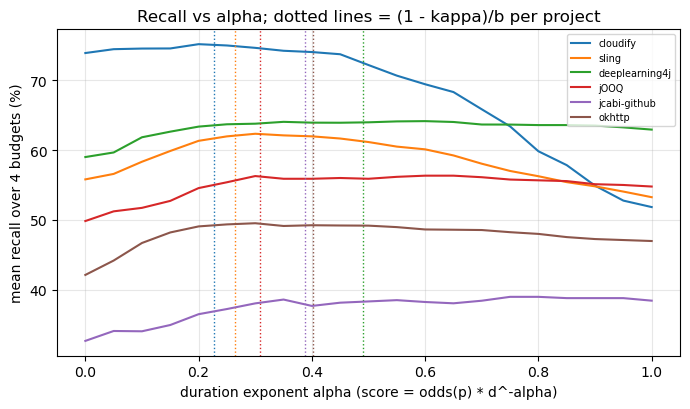

In [6]:
# STEP 5 (E3) — Theory: how much should duration count?
# Within a cycle, suppose P(fail) ~ exp(a_c + b*x + kappa*log d), where x = logit(p) is the model score.
# The greedy knapsack order (expected failures per second) is then  b*x + (kappa - 1)*log d, i.e.
#     score = odds(p) * d^(-alpha*)   with   alpha* = (1 - kappa) / b.
#   b     = within-cycle calibration slope of the transferred logit (b > 1: logits too compressed),
#   kappa = duration elasticity of failure (kappa > 0: long tests fail more, beyond what x captures).
# b and kappa come from a conditional (per-cycle) logistic fit; the cycle intercepts a_c drop out, which is
# exactly why prevalence does not matter. Here we fit them with labels (oracle) and check the prediction
# against the empirically best alpha. Step 6 estimates them without target labels.
grid = np.round(np.arange(0, 1.01, 0.05), 2)
C = CycleSet(scored["build"][scored["build"]["set_confirm"]])
p = C.frame["p_ens"].clip(EPS, 1 - EPS).to_numpy(); x = logit(p); odds = p / (1 - p)
curves = pd.DataFrame({a: C.by_project(C.recall(odds * C.est ** -a, seeds=5).mean(axis=1)).iloc[:, 0] * 100 for a in grid})
rows = []
for pr in curves.index:
    cyc_pr = np.flatnonzero(C.cyc_project == pr)
    b_only, _ = C.conditional_slope(x, mask_cycles=cyc_pr, with_duration=False)
    b, k = C.conditional_slope(x, mask_cycles=cyc_pr, with_duration=True)
    a_th = float(np.clip((1 - k) / b, 0, 1)); a_near = grid[np.argmin(np.abs(grid - a_th))]
    rows.append({"project": pr, "b (x only)": b_only, "b": b, "kappa": k, "alpha_theory": a_th,
                 "alpha_best": float(curves.loc[pr].idxmax()), "recall@theory": curves.loc[pr, a_near],
                 "recall@best": curves.loc[pr].max(), f"recall@{HYBRID_ALPHA_PAPER}": curves.loc[pr, HYBRID_ALPHA_PAPER],
                 "recall@1": curves.loc[pr, 1.0], "recall@0": curves.loc[pr, 0.0]})
E3 = pd.DataFrame(rows).set_index("project")
display(E3.round(3))
print("Mean regret of alpha_theory vs best (points):", round((E3["recall@best"] - E3["recall@theory"]).mean(), 2),
      "| alpha = 1:", round((E3["recall@best"] - E3["recall@1"]).mean(), 2),
      "| alpha = 0:", round((E3["recall@best"] - E3["recall@0"]).mean(), 2),
      f"| alpha = {HYBRID_ALPHA_PAPER}:", round((E3["recall@best"] - E3[f"recall@{HYBRID_ALPHA_PAPER}"]).mean(), 2))
print("Spearman(alpha_theory, alpha_best) over projects:", round(spearmanr(E3["alpha_theory"], E3["alpha_best"])[0], 2))
E3.to_csv(OUT / "E3_theory_vs_best_alpha.csv"); curves.to_csv(OUT / "E3_alpha_curves.csv")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4.2))
for pr in curves.index:
    line, = ax.plot(curves.columns, curves.loc[pr], label=pr.split("@")[-1])
    ax.axvline(E3.loc[pr, "alpha_theory"], color=line.get_color(), linestyle=":", linewidth=1)
ax.set_xlabel("duration exponent alpha (score = odds(p) * d^-alpha)")
ax.set_ylabel("mean recall over 4 budgets (%)")
ax.set_title("Recall vs alpha; dotted lines = (1 - kappa)/b per project")
ax.legend(fontsize=7); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(OUT / "E3_alpha_curves.png", dpi=200); plt.show()


## Step 5b (E3b) — The same quantities in-domain
**Look for.** In-domain b < 1 and the best α ≥ 1, the opposite of the transfer case. This one contrast explains why
p/d works in-domain and fails after transfer. In-domain probabilities are not small (≈ 35%), so (1−κ)/b overshoots
the magnitude there; report the direction, not the exact value.

Note the first line: ABB durations never change for a test, so in-domain duration estimates are exact. Add this
to the threats section.

In [7]:
# STEP 5b (E3b) — The same quantities IN-DOMAIN (ABB, chronological expanding folds as in Cell 8).
# Expected contrast: in-domain b < 1 and alpha* >= 1 (full division by duration is right), after transfer
# b > 1 and alpha* < 1. This explains why the rule works in-domain and fails after transfer.
# Note: ABB durations are constant per test (checked below), so in-domain estimated = realised duration.
which = ("gradient_boosting", "random_forest", "knn", "svm") if IN_DOMAIN_SVM else ("gradient_boosting", "random_forest", "knn")
parts = []
for pr, g in train.groupby("project"):
    cyc = np.sort(g["cycle_position"].unique()); n = len(cyc)
    cut = np.linspace(int(n * 0.5), n, 6, dtype=int)
    for k in range(5):
        tr = g[g["cycle_position"].isin(cyc[:cut[k]])]
        te = g[g["cycle_position"].isin(cyc[cut[k]:cut[k + 1]])].copy()
        m = fit_transfer_models(tr, which=which)
        te["p_ens"] = score_models(m, te).mean(axis=1).to_numpy()
        te["estimated_duration"] = te["previous_duration"].fillna(tr["previous_duration"].median()).clip(lower=1)
        parts.append(te.assign(fold=k + 1))
oof = pd.concat(parts)
oof = oof[oof.groupby(["project", "cycle_position"])["failure"].transform("max") == 1]
print("Tests whose duration ever changes:", int((abb.groupby(["project", "test_id"])["observed_duration_mean"].nunique() > 1).sum()))
Ci = CycleSet(oof)
pi_ = Ci.frame["p_ens"].clip(EPS, 1 - EPS).to_numpy()
print(f"In-domain mean predicted {pi_.mean():.3f} vs observed {Ci.y.mean():.3f} ({Ci.n_cyc} failure cycles)")
grid_in = np.round(np.arange(0, 2.01, 0.1), 2)
curves_in = pd.DataFrame({a: Ci.by_project(Ci.recall((pi_ / (1 - pi_)) * Ci.est ** -a, seeds=5).mean(axis=1)).iloc[:, 0] * 100 for a in grid_in})
rows = []
for pr in curves_in.index:
    b, k = Ci.conditional_slope(logit(pi_), mask_cycles=np.flatnonzero(Ci.cyc_project == pr))
    rows.append({"project": pr, "b": b, "kappa": k, "alpha_theory": (1 - k) / b, "alpha_best": float(curves_in.loc[pr].idxmax()),
                 "recall@best": curves_in.loc[pr].max(), "recall@1": curves_in.loc[pr, 1.0], "recall@0.2": curves_in.loc[pr, 0.2]})
E3b = pd.DataFrame(rows).set_index("project")
display(E3b.round(3)); display(curves_in.round(2))
E3b.to_csv(OUT / "E3b_in_domain.csv"); curves_in.to_csv(OUT / "E3b_in_domain_curves.csv")


Tests whose duration ever changes: 0
In-domain mean predicted 0.338 vs observed 0.233 (290 failure cycles)


,b,kappa,alpha_theory,alpha_best,recall@best,recall@1,recall@0.2
project,,,,,,,
IOF-ROL,0.447,0.030,2.172,1.1,42.967,42.795,39.797
Paint-Control,0.344,0.027,2.826,1.2,72.766,72.672,70.169


,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,...,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0
project,,,,,,,,,,,,,,,,,,,,,
IOF-ROL,37.43,38.58,39.80,40.34,40.75,41.28,41.66,42.11,42.49,42.63,...,42.97,42.96,42.95,42.83,42.83,42.89,42.91,42.73,42.70,42.58
Paint-Control,66.90,68.94,70.17,70.64,71.38,71.60,72.08,72.18,72.44,72.59,...,72.68,72.77,71.98,71.95,71.80,71.68,70.75,70.11,69.89,69.80


## Step 6 (E4) — Setting α without the target's labels (RQ3)
**Why.** α = 0.2 was chosen on cycles of the same six projects, so it is not zero-shot per project.
Leave-one-target-out (LOTO) estimates b and κ on the **selection** cycles of the other five projects only and
evaluates on the target's **confirmatory** cycles. First-K uses the target's own first K failure cycles.

**Look for.** LOTO versus fixed 0.2 and versus the oracle per-project best. First-K estimates are usually unstable
(early cycles differ from later ones); if so, recommend LOTO and say why.

In [8]:
# STEP 6 (E4) — A deployable exponent: estimate alpha* = (1 - kappa)/b WITHOUT the target's labels.
#  - leave-one-target-out (LOTO): fit b and kappa on the SELECTION cycles of the other five projects only;
#    the target project contributes nothing (strictly zero-shot for the target);
#  - first-K: fit on the target's own first K failure cycles (needs a few labelled cycles; K = 10, 25, 50);
#  - fixed alpha = 0.2 (the draft: chosen on cycles of the same six projects, so not zero-shot per project).
# Evaluation: confirmatory cycles. For first-K, only confirmatory cycles AFTER the K-th failure cycle count.
S = CycleSet(scored["build"][scored["build"]["set_selection"]])
xs = logit(S.frame["p_ens"].clip(EPS, 1 - EPS).to_numpy())
E = CycleSet(scored["build"][scored["build"]["set_early"]])
xe = logit(E.frame["p_ens"].clip(EPS, 1 - EPS).to_numpy())
C = CycleSet(scored["build"][scored["build"]["set_confirm"]])
p = C.frame["p_ens"].clip(EPS, 1 - EPS).to_numpy(); odds = p / (1 - p)

alpha_loto, rows = {}, []
for pr in np.unique(C.cyc_project):
    b, k = S.conditional_slope(xs, mask_cycles=np.flatnonzero(S.cyc_project != pr))
    alpha_loto[pr] = float(np.clip((1 - k) / b, 0, 1))
    rows.append({"project": pr, "method": "LOTO", "K": None, "b": b, "kappa": k, "alpha": alpha_loto[pr]})
    order = np.argsort(E.cyc_position[E.cyc_project == pr])
    early_cycles = np.flatnonzero(E.cyc_project == pr)[order]
    for K in [10, 25, 50]:
        if len(early_cycles) >= K:
            b, k = E.conditional_slope(xe, mask_cycles=early_cycles[:K])
            rows.append({"project": pr, "method": "first-K", "K": K, "b": b, "kappa": k, "alpha": float(np.clip((1 - k) / b, 0, 1)),
                         "after_position": E.cyc_position[early_cycles[K - 1]]})
alphas = pd.DataFrame(rows)
display(alphas.round(3))

def alpha_vector(mapping):
    return np.array([mapping[pr] for pr in C.frame["project"]])

def eval_alpha(alpha_per_row, cycle_mask=None):
    r = C.recall(odds * C.est ** -alpha_per_row, seeds=TIE_SEEDS)
    if cycle_mask is not None:
        r = np.where(cycle_mask[:, None], r, np.nan)
    return r

res = {}
res["alpha = 0 (EnsembleRisk)"] = eval_alpha(np.zeros(len(p)))
res["alpha = 1 (odds/d)"] = eval_alpha(np.ones(len(p)))
res[f"alpha = {HYBRID_ALPHA_PAPER} (draft, tuned on same projects)"] = eval_alpha(np.full(len(p), HYBRID_ALPHA_PAPER))
res["alpha = LOTO (1-kappa)/b  [proposed]"] = eval_alpha(alpha_vector(alpha_loto))
oracle_alpha = {pr: E3.loc[pr, "alpha_best"] for pr in E3.index}
res["alpha = per-project best (oracle)"] = eval_alpha(alpha_vector(oracle_alpha))
tab = pd.DataFrame({k: equal_weight(C, v) for k, v in res.items()}).T
tab.columns = ["10%", "20%", "30%", "50%"]; tab["mean"] = tab.mean(axis=1)
display(tab.round(2))

rowsK = []
for K in [10, 25, 50]:
    sub = alphas[(alphas["method"] == "first-K") & (alphas["K"] == K)].set_index("project")
    if len(sub) < len(np.unique(C.cyc_project)):
        continue
    after = sub["after_position"].reindex(C.cyc_project).to_numpy()
    mask = C.cyc_position > after
    for name, amap in [(f"first-{K}", sub["alpha"].to_dict()), ("LOTO", alpha_loto),
                       (f"fixed {HYBRID_ALPHA_PAPER}", {pr: HYBRID_ALPHA_PAPER for pr in sub.index})]:
        r = eval_alpha(alpha_vector(amap), mask)
        rowsK.append({"K": K, "alpha source": name, "cycles": int(mask.sum()),
                      **dict(zip(["10%", "20%", "30%", "50%"], equal_weight(C, r)))})
E4K = pd.DataFrame(rowsK)
display(E4K.round(2))
alphas.to_csv(OUT / "E4_alpha_estimates.csv", index=False); tab.to_csv(OUT / "E4_deployable_alpha.csv"); E4K.to_csv(OUT / "E4_firstK.csv", index=False)


,project,method,K,b,kappa,alpha,after_position
0,CloudifySource@cloudify,LOTO,NaN,2.069,0.286,0.345,NaN
1,CloudifySource@cloudify,first-K,10.0,6.931,-0.106,0.160,229.0
2,CloudifySource@cloudify,first-K,25.0,8.403,-0.121,0.133,256.0
3,CloudifySource@cloudify,first-K,50.0,1.838,0.143,0.466,309.0
4,apache@sling,LOTO,NaN,2.161,0.225,0.359,NaN
5,apache@sling,first-K,10.0,20.724,3.579,0.000,9.0
6,apache@sling,first-K,25.0,2.536,0.329,0.265,83.0
7,apache@sling,first-K,50.0,1.335,0.183,0.612,153.0
8,deeplearning4j@deeplearning4j,LOTO,NaN,2.170,0.366,0.292,NaN
9,deeplearning4j@deeplearning4j,first-K,10.0,1.421,0.052,0.667,13.0


,10%,20%,30%,50%,mean
alpha = 0 (EnsembleRisk),38.46,49.03,57.07,64.22,52.20
alpha = 1 (odds/d),34.49,47.31,55.40,68.15,51.34
"alpha = 0.2 (draft, tuned on same projects)",41.96,53.12,61.65,69.82,56.64
alpha = LOTO (1-kappa)/b [proposed],42.44,54.55,62.41,70.11,57.38
alpha = per-project best (oracle),42.76,54.56,62.98,70.59,57.72


,K,alpha source,cycles,10%,20%,30%,50%
0,10,first-10,2091,40.38,52.01,60.38,66.99
1,10,LOTO,2091,42.37,54.41,62.28,70.03
2,10,fixed 0.2,2091,41.96,53.23,61.66,69.73
3,25,first-25,2062,41.29,53.41,61.61,68.53
4,25,LOTO,2062,42.12,54.28,62.18,69.82
5,25,fixed 0.2,2062,41.84,53.20,61.56,69.52
6,50,first-50,1992,39.98,52.17,59.63,66.58
7,50,LOTO,1992,41.71,53.62,61.42,69.02
8,50,fixed 0.2,1992,41.27,52.61,61.11,68.59


## Step 7 (E5) — Strong baselines (RQ3/RQ4)
**Why.** Any CI-prioritisation reviewer will ask for a recency baseline. EWMA (λ = 0.2) of a test's past verdicts
is training-free; `EWMA·d^-0.25` is its cost-aware version. The draft's HistoricalFailure ranks new tests last,
while Table VII's code used the smoothed rate (F+0.5)/(n+1), which ranks them first; both are shown so the text
can be corrected.

**Look for.** Where the proposed score stands relative to EWMA and EWMA·d^-0.25, overall and per project.
**Report this honestly whichever way it goes**: if the recency baseline wins, the contribution is the mechanism and
the exponent rule (Steps 4–6), not a new best prioritiser.

In [9]:
# STEP 7 (E5) — Strong baselines under the corrected protocol (build-level history, realised budgets,
# random ties, equal project weight). Reviewers will ask for a recency baseline: EWMA of past verdicts
# (lambda = 0.2) is training-free and is the standard bar in CI prioritisation. We use it ONLY as a baseline.
# Also: the draft's Table VII used the smoothed rate (F + 0.5)/(n + 1) in code, so new tests rank FIRST,
# while the text says they rank last. Both versions are reported so the text can be fixed.
C = CycleSet(scored["build"][scored["build"]["set_confirm"]])
f = C.frame
p = f["p_ens"].clip(EPS, 1 - EPS).to_numpy(); odds = p / (1 - p)
p_prior = C.per_cycle_shift(p, C.paper_prior_target())
F = f["historical_failure_count"].fillna(0).to_numpy(); n = f["historical_execution_count"].fillna(0).to_numpy()
ew = f["ewma"].to_numpy()
a_loto = alpha_vector(alpha_loto)
STRATS = {
    "Random": np.zeros(len(p)),
    "ShortestFirst": -C.est,
    "HistoricalFailure (new tests last)": f["historical_failure_percentage"].fillna(0).to_numpy(),
    "HistoricalFailure smoothed (F+.5)/(n+1)": (F + 0.5) / (n + 1),
    "History smoothed / d": (F + 0.5) / (n + 1) / C.est,
    "EWMA": ew,
    "EWMA * d^-0.25": (ew + 1e-3) * C.est ** -0.25,
    "EWMA / d": (ew + 1e-3) / C.est,
    "EnsembleRisk": p,
    "RiskPerTime (raw)": p / C.est,
    f"Hybrid draft (p~ d^-{HYBRID_ALPHA_PAPER})": p_prior * C.est ** -HYBRID_ALPHA_PAPER,
    "Proposed: odds * d^-alpha_LOTO": odds * C.est ** -a_loto,
}
R = {k: C.recall(v, seeds=TIE_SEEDS) for k, v in STRATS.items()}
E5 = pd.DataFrame({k: equal_weight(C, v) for k, v in R.items()}).T
E5.columns = ["10%", "20%", "30%", "50%"]; E5["mean"] = E5.mean(axis=1)
display(E5.round(2))
per_project_30 = pd.DataFrame({k: C.by_project(v).iloc[:, 2] * 100 for k, v in R.items()}).T
display(per_project_30.round(1))
E5.to_csv(OUT / "E5_baselines_equal_weight.csv"); per_project_30.to_csv(OUT / "E5_baselines_per_project_30.csv")


,10%,20%,30%,50%,mean
Random,8.99,16.33,24.15,37.70,21.79
ShortestFirst,21.24,30.42,38.05,50.46,35.04
HistoricalFailure (new tests last),35.64,46.96,58.17,65.87,51.66
HistoricalFailure smoothed (F+.5)/(n+1),36.27,48.12,59.28,66.73,52.60
History smoothed / d,36.53,49.73,60.86,70.82,54.48
EWMA,43.93,56.52,64.94,71.08,59.12
EWMA * d^-0.25,45.84,58.85,67.08,73.48,61.31
EWMA / d,44.95,58.23,66.09,73.35,60.65
EnsembleRisk,38.46,49.03,57.07,64.22,52.20
RiskPerTime (raw),27.27,40.60,49.89,60.58,44.58


project,CloudifySource@cloudify,apache@sling,deeplearning4j@deeplearning4j,jOOQ@jOOQ,jcabi@jcabi-github,square@okhttp
Random,29.3,24.6,30.6,20.3,16.3,23.8
ShortestFirst,27.3,30.0,50.5,44.1,40.6,35.9
HistoricalFailure (new tests last),81.6,63.2,61.4,54.6,34.2,54.1
HistoricalFailure smoothed (F+.5)/(n+1),83.0,63.5,64.3,52.7,36.4,55.8
History smoothed / d,75.4,66.3,74.2,53.3,40.2,55.6
EWMA,89.5,77.6,68.5,53.4,42.0,58.6
EWMA * d^-0.25,90.0,74.9,72.8,59.4,42.4,63.0
EWMA / d,87.3,71.9,74.3,59.4,41.7,62.0
EnsembleRisk,80.0,59.8,69.5,52.0,32.6,48.5
RiskPerTime (raw),38.7,40.5,71.0,58.7,39.8,50.5


## Step 8 (E6) — Where does the slope come from? (RQ2)
**Look for.** Class weighting changes the *inflation* (pred/obs) a lot but b, α\* and recall little, which is
direct evidence that prevalence is not the issue. Dropping the duration-rank feature tests whether duration enters
twice (once in p, once in the divisor). Single models show the effect is not an ensemble artefact.

In [10]:
# STEP 8 (E6) — Where does the slope come from? Source-side ablations (retrain on ABB, score the same cycles).
# Each variant reports: predicted/observed failure ratio (scale), within-cycle AUC (ranking), b and kappa
# (within-cycle shape), alpha* = (1-kappa)/b, and recall of p/d, odds/d and odds*d^-alpha*.
# SVM is left out of every variant to keep run time low; the reference row is the ensemble WITHOUT SVM.
C = CycleSet(scored["build"][scored["build"]["set_confirm"]])
frame_c = C.frame.copy()
no_dur = [c for c in FEATURES if c != "rank_previous_duration"]
variants = {
    "ensemble GB+RF+kNN (reference)": dict(which=("gradient_boosting", "random_forest", "knn")),
    "no class weighting": dict(which=("gradient_boosting", "random_forest", "knn"), class_weight=False),
    "without duration-rank feature": dict(which=("gradient_boosting", "random_forest", "knn"), features=no_dur),
    "without k-NN (GB+RF)": dict(which=("gradient_boosting", "random_forest")),
    "gradient boosting only": dict(which=("gradient_boosting",)),
    "logistic regression only": dict(which=("logistic",)),
}
rows = []
for name, kw in variants.items():
    feats = kw.get("features", FEATURES)
    m = fit_transfer_models(train, class_weight=kw.get("class_weight", True), features=feats, which=kw["which"])
    pv = np.clip(score_models(m, frame_c, features=feats).mean(axis=1).to_numpy(), EPS, 1 - EPS)
    o = pv / (1 - pv)
    b, k = C.conditional_slope(logit(pv))
    a = float(np.clip((1 - k) / b, 0, 1))
    row = {"variant": name, "pred/obs": pv.mean() / C.y.mean(),
           "within-cycle AUC": np.nanmean(C.by_project(C.within_cycle_auc(pv)).iloc[:, 0]),
           "b": b, "kappa": k, "alpha*": a}
    for label, s in [("p", pv), ("p/d", pv / C.est), ("odds/d", o / C.est), ("odds*d^-alpha*", o * C.est ** -a)]:
        row[f"recall {label}"] = equal_weight(C, C.recall(s, seeds=5)).mean()
    rows.append(row)
    print(f"done: {name}")
E6 = pd.DataFrame(rows).set_index("variant")
display(E6.round(3))
E6.to_csv(OUT / "E6_source_ablations.csv")


done: ensemble GB+RF+kNN (reference)
done: no class weighting
done: without duration-rank feature
done: without k-NN (GB+RF)
done: gradient boosting only
done: logistic regression only


,pred/obs,within-cycle AUC,b,kappa,alpha*,recall p,recall p/d,recall odds/d,recall odds*d^-alpha*
variant,,,,,,,,,
ensemble GB+RF+kNN (reference),12.655,0.884,1.670,0.352,0.388,52.200,44.270,52.872,57.368
no class weighting,6.706,0.885,1.503,0.351,0.432,52.385,47.852,53.865,57.364
without duration-rank feature,12.339,0.868,1.478,0.390,0.413,51.883,44.450,51.995,56.293
without k-NN (GB+RF),15.657,0.896,1.641,0.345,0.399,53.269,43.690,53.206,57.762
gradient boosting only,17.538,0.890,1.682,0.373,0.373,54.173,43.233,53.058,57.847
logistic regression only,20.034,0.667,2.105,0.760,0.114,50.157,40.296,44.627,52.286


## Step 9 (E7) — Early failure cycles
**Why.** The draft motivates zero-shot transfer by onboarding, but its cycles come from whole histories.
**Look for.** Whether transfer beats the recency baseline in the first 10/25/50 failure cycles. Check the median
history length printed below: in most projects the first failure cycles already have long histories, so this is
not a true cold start. Describe it as such, or keep the onboarding claim out of the paper.

In [11]:
# STEP 9 (E7) — Early cycles: is transfer worth it while a project's history is short?
# The draft motivates zero-shot transfer by onboarding, but its cycles are drawn from the whole history
# (median history per test is in the hundreds of runs). Here: the first N_EARLY failure cycles of every
# project, in windows, against the recency baseline. Samples are small (10-25 cycles per project and
# window), so treat this as descriptive and report it as such.
E = CycleSet(scored["build"][scored["build"]["set_early"]])
fe = E.frame
k_index = pd.Series(E.cyc_position).groupby(E.cyc_project).rank(method="first").to_numpy()   # 1 = first failure cycle
p = fe["p_ens"].clip(EPS, 1 - EPS).to_numpy(); odds = p / (1 - p); ew = fe["ewma"].to_numpy()
F = fe["historical_failure_count"].fillna(0).to_numpy(); n = fe["historical_execution_count"].fillna(0).to_numpy()
a_e = np.array([alpha_loto[pr] for pr in fe["project"]])
strats = {"EnsembleRisk": p, "Proposed: odds * d^-alpha_LOTO": odds * E.est ** -a_e, "EWMA": ew,
          "EWMA * d^-0.25": (ew + 1e-3) * E.est ** -0.25, "HistoricalFailure smoothed": (F + 0.5) / (n + 1),
          "ShortestFirst": -E.est, "Random": np.zeros(len(p))}
R = {k: E.recall(v, seeds=TIE_SEEDS) for k, v in strats.items()}
rows = []
for lo, hi in [(1, 10), (11, 25), (26, N_EARLY)]:
    mask = (k_index >= lo) & (k_index <= hi)
    for k, r in R.items():
        rows.append({"window": f"failure cycles {lo}-{hi}", "strategy": k, "cycles": int(mask.sum()),
                     **dict(zip(["10%", "20%", "30%", "50%"], equal_weight(E, np.where(mask[:, None], r, np.nan))))})
E7 = pd.DataFrame(rows)
display(E7.pivot_table(index="strategy", columns="window", values="30%", sort=False).round(1))
med_hist = fe.groupby("project")["historical_execution_count"].median()
print("Median earlier runs per test in these early failure cycles:\n", med_hist.to_string())
E7.to_csv(OUT / "E7_early_cycles.csv", index=False)


window,failure cycles 1-10,failure cycles 11-25,failure cycles 26-50
strategy,,,
EnsembleRisk,67.9,60.6,52.3
Proposed: odds * d^-alpha_LOTO,74.4,67.8,68.1
EWMA,75.0,63.4,62.5
EWMA * d^-0.25,78.9,67.2,70.7
HistoricalFailure smoothed,72.0,61.0,64.8
ShortestFirst,63.5,58.2,63.2
Random,32.6,29.6,27.8


Median earlier runs per test in these early failure cycles:
 project
CloudifySource@cloudify          254.0
apache@sling                      73.0
deeplearning4j@deeplearning4j     53.0
jOOQ@jOOQ                        360.0
jcabi@jcabi-github               346.0
square@okhttp                     11.5


## Step 10 (E8) — Position metrics and a two-stage order (RQ4)
**Why.** The draft's main drawback is APFD. The two-stage order runs the top 5% most likely failures first, then
the cost-aware order. **Look for.** How much APFD the two-stage order recovers and how much recall it gives up.

In [12]:
# STEP 10 (E8) — Position metrics and a two-stage order that protects APFD.
# Two-stage: run the k most likely failures first (k = 5% of the cycle, at least 1), then the cost-aware order.
C = CycleSet(scored["build"][scored["build"]["set_confirm"]])
f = C.frame
p = f["p_ens"].clip(EPS, 1 - EPS).to_numpy(); odds = p / (1 - p); ew = f["ewma"].to_numpy()
p_prior = C.per_cycle_shift(p, C.paper_prior_target())
prop = odds * C.est ** -alpha_vector(alpha_loto)
rank_p = pd.Series(-p).groupby(C.cyc).rank(method="first").to_numpy()
k_first = np.maximum(1, np.ceil(0.05 * C.size[C.cyc]))
two_stage = np.where(rank_p <= k_first, 1e12 + p, prop)   # top-k by p first, then the proposed order
strats = {"EnsembleRisk": p, "EWMA": ew, f"Hybrid draft (p~ d^-{HYBRID_ALPHA_PAPER})": p_prior * C.est ** -HYBRID_ALPHA_PAPER,
          "Proposed: odds * d^-alpha_LOTO": prop, "Two-stage: top-5% by p, then proposed": two_stage,
          "RiskPerTime (prior) p~/d": p_prior / C.est, "ShortestFirst": -C.est, "Random": np.zeros(len(p))}
rows, per_cycle = [], {}
for k, s in strats.items():
    apfd, apfdc = C.order_metrics(s, seeds=TIE_SEEDS)
    rec = C.recall(s, seeds=TIE_SEEDS)
    per_cycle[k] = {"APFD": apfd, "APFDc": apfdc, "recall30": rec[:, 2]}
    rows.append({"strategy": k, "APFD": equal_weight(C, apfd).iloc[0], "APFDc": equal_weight(C, apfdc).iloc[0],
                 **dict(zip(["recall 10%", "recall 20%", "recall 30%", "recall 50%"], equal_weight(C, rec)))})
E8 = pd.DataFrame(rows).set_index("strategy")
display(E8.round(2))
E8.to_csv(OUT / "E8_order_metrics.csv")


,APFD,APFDc,recall 10%,recall 20%,recall 30%,recall 50%
strategy,,,,,,
EnsembleRisk,84.63,74.55,38.46,49.03,57.07,64.22
EWMA,88.15,79.28,43.93,56.52,64.94,71.08
Hybrid draft (p~ d^-0.2),72.82,78.33,41.99,53.20,61.75,69.93
Proposed: odds * d^-alpha_LOTO,67.07,78.56,42.44,54.55,62.41,70.11
"Two-stage: top-5% by p, then proposed",74.24,77.59,40.14,51.89,60.48,69.26
RiskPerTime (prior) p~/d,37.77,73.80,34.38,47.20,54.62,67.94
ShortestFirst,22.76,58.51,21.24,30.42,38.05,50.46
Random,49.77,49.77,8.99,16.33,24.15,37.70


## Step 11 (E9) — Statistics for the paper
Per project: Wilcoxon on cycles, Holm within each contrast (6 projects × 4 budgets). Across projects: a
hierarchical bootstrap CI (resample projects, then cycles) of the equal-weight difference. Put the CI column in the
main results table; say "significant in k of 6 projects" rather than pooling 2,111 cycles as independent.

In [13]:
# STEP 11 (E9) — Statistics for the paper: per-project Wilcoxon (Holm) and a hierarchical bootstrap CI
# (resample projects, then cycles) for the equal-project-weight mean difference. Projects, not pooled
# cycles, carry the headline claims; with 6 projects the bootstrap CI is the honest summary.
C = CycleSet(scored["build"][scored["build"]["set_confirm"]])
contrasts = [("Proposed: odds * d^-alpha_LOTO", "EnsembleRisk"),
             ("Proposed: odds * d^-alpha_LOTO", f"Hybrid draft (p~ d^-{HYBRID_ALPHA_PAPER})"),
             ("Proposed: odds * d^-alpha_LOTO", "EWMA"),
             ("Proposed: odds * d^-alpha_LOTO", "EWMA * d^-0.25"),
             ("EWMA", "EnsembleRisk")]
recall_all = {k: C.recall(v, seeds=TIE_SEEDS) for k, v in STRATS.items()}   # STRATS from Step 7 (same cycles)
rows = []
for a, b in contrasts:
    for j, bud in enumerate(BUDGETS):
        d = (recall_all[a][:, j] - recall_all[b][:, j]) * 100
        point, lo, hi = hierarchical_bootstrap(d, C.cyc_project, n_boot=2000)
        for pr in np.unique(C.cyc_project):
            st = paired(recall_all[a][C.cyc_project == pr, j], recall_all[b][C.cyc_project == pr, j])
            rows.append({"contrast": f"{a}  vs  {b}", "budget": f"{int(bud*100)}%", "project": pr,
                         "mean_diff_pts": st["mean_diff"] * 100, "improved": st["improved"], "worse": st["worse"],
                         "p": st["p"], "rank_biserial": st["rb"], "eq_weight_diff": point, "ci_low": lo, "ci_high": hi})
E9 = pd.DataFrame(rows)
E9["p_holm"] = np.nan
for c in E9["contrast"].unique():
    m = E9["contrast"] == c
    E9.loc[m, "p_holm"] = holm(E9.loc[m, "p"].to_numpy())   # Holm within each contrast (6 projects x 4 budgets)
summary = (E9.groupby(["contrast", "budget"], sort=False)
             .agg(eq_weight_diff=("eq_weight_diff", "first"), ci_low=("ci_low", "first"), ci_high=("ci_high", "first"),
                  projects_better=("mean_diff_pts", lambda s: int((s > 0).sum())),
                  projects_sig_better=("p_holm", lambda s: int(((E9.loc[s.index, "mean_diff_pts"] > 0) & (s < 0.05)).sum())),
                  projects_sig_worse=("p_holm", lambda s: int(((E9.loc[s.index, "mean_diff_pts"] < 0) & (s < 0.05)).sum()))))
display(summary.round(2))
E9.to_csv(OUT / "E9_per_project_tests.csv", index=False); summary.to_csv(OUT / "E9_summary.csv")


eq_weight_diff  \
contrast                                           budget                   
Proposed: odds * d^-alpha_LOTO  vs  EnsembleRisk   10%               3.98   
                                                   20%               5.52   
                                                   30%               5.34   
                                                   50%               5.89   
Proposed: odds * d^-alpha_LOTO  vs  Hybrid draf... 10%               0.45   
                                                   20%               1.35   
                                                   30%               0.66   
                                                   50%               0.18   
Proposed: odds * d^-alpha_LOTO  vs  EWMA           10%              -1.48   
                                                   20%              -1.97   
                                                   30%              -2.53   
                                                   50%              -0.97   
Proposed: odds * d^-alpha_LOTO  vs  EWMA * d^-0.25 10%              -3.40   
                                                   20%              -4.30   
                                                   30%              -4.67   
                                                   50%              -3.37   
EWMA  vs  EnsembleRisk                             10%               5.46   
                                                   20%               7.49   
                                                   30%               7.87   
                                                   50%               6.86   

                                                           ci_low  ci_high  \
contrast                                           budget                    
Proposed: odds * d^-alpha_LOTO  vs  EnsembleRisk   10%       1.60     6.14   
                                                   20%       3.07     7.97   
                                                   30%       2.64     8.13   
                                                   50%       3.23     8.75   
Proposed: odds * d^-alpha_LOTO  vs  Hybrid draf... 10%      -0.75     1.64   
                                                   20%      -0.29     3.53   
                                                   30%      -0.76     2.24   
                                                   50%      -0.74     1.15   
Proposed: odds * d^-alpha_LOTO  vs  EWMA           10%      -5.98     3.10   
                                                   20%      -7.89     3.55   
                                                   30%      -8.43     2.65   
                                                   50%      -7.20     3.86   
Proposed: odds * d^-alpha_LOTO  vs  EWMA * d^-0.25 10%      -6.71    -0.43   
                                                   20%      -9.08     0.25   
                                                   30%      -8.62    -1.01   
                                                   50%      -6.96    -0.52   
EWMA  vs  EnsembleRisk                             10%       1.51     9.71   
                                                   20%       2.75    13.19   
                                                   30%       2.96    13.49   
                                                   50%       2.29    12.58   

                                                           projects_better  \
contrast                                           budget                    
Proposed: odds * d^-alpha_LOTO  vs  EnsembleRisk   10%                   6   
                                                   20%                   6   
                                                   30%                   5   
                                                   50%                   6   
Proposed: odds * d^-alpha_LOTO  vs  Hybrid draf... 10%                   4   
                                                   20%                   5   
                       

## Step 12 (E10, optional, recommended) — All eligible RTPTorrent projects
**Why.** With six projects every project-level claim is descriptive. Adding every project that meets an explicit
rule (≥ 50 failure cycles, ≤ 50% zero durations) gives a real project-level test and replaces "skipped because the
CSV exceeds 400 MB" with a stated criterion. All failure cycles are evaluated, so no α is tuned on target cycles.

**Look for.** Spearman(α_theory, α_best) across projects and the project-level Wilcoxon table.

In [14]:
# STEP 12 (E10, optional but strongly recommended for MSR) — More target projects.
# Six projects make every project-level claim descriptive. RTPTorrent has 20 projects; this cell adds every
# project that meets an explicit rule: >= MIN_FAIL_CYCLES failure cycles, zero-duration share <= 50%
# (excludes facebook/buck), and a CSV we can load (SonarQube, 1.3 GB, only with INCLUDE_SONARQUBE = True).
# All failure cycles of every project are evaluated (no sampling), so no alpha is tuned on target cycles.
# The ensemble without SVM is used here for run time; Step 8 shows whether SVM matters.
MIN_FAIL_CYCLES = 50
INCLUDE_SONARQUBE = False
E10_WHICH = ("gradient_boosting", "random_forest", "knn")

def build_rtp_cycle_table(project):
    """Cell 21C for one project (same column names as rtp_cycle_table.pkl)."""
    path = RTP_DIR / project / f"{project}.csv"
    df = pd.read_csv(path, usecols=["travisJobId", "testName", "duration", "failures", "errors"],
                     dtype={"travisJobId": "int64", "testName": "string"})
    df = df.drop_duplicates(["travisJobId", "testName"]).copy()
    df["actualfailure"] = ((df["failures"].fillna(0) + df["errors"].fillna(0)) > 0).astype(int)
    df["observedduration"] = df["duration"].fillna(0).clip(lower=0)
    order = {j: i for i, j in enumerate(sorted(df["travisJobId"].unique()))}
    df["cycleposition"] = df["travisJobId"].map(order)
    df = df.sort_values(["testName", "cycleposition"]).reset_index(drop=True)
    g = df.groupby("testName", sort=False)
    runs = g.cumcount().replace(0, np.nan)
    est = (g["observedduration"].cumsum() - df["observedduration"]) / runs
    fallback = df.loc[df["observedduration"] > 0, "observedduration"].median()
    df["estimatedduration"] = est.fillna(fallback).clip(lower=1e-3)
    df["project"] = project
    df["testid"] = df["testName"].astype(str)
    return df[["project", "travisJobId", "cycleposition", "testid", "actualfailure", "observedduration", "estimatedduration"]]

existing = set(rtp_cycles["project"].unique())
candidates = sorted(d.name for d in RTP_DIR.iterdir() if d.is_dir() and (d / f"{d.name}.csv").exists())
if not INCLUDE_SONARQUBE:
    candidates = [c for c in candidates if c != "SonarSource@sonarqube"]
m_ext = models if not USE_SVM else fit_transfer_models(train, which=E10_WHICH)
tables, inclusion = {}, []
for project in candidates:
    t = rtp_cycles[rtp_cycles["project"] == project] if project in existing else build_rtp_cycle_table(project)
    zero_share = float((t["observedduration"] <= 0).mean())
    n_fc = int(t.groupby("cycleposition")["actualfailure"].max().sum())
    ok = n_fc >= MIN_FAIL_CYCLES and zero_share <= 0.5
    inclusion.append({"project": project, "failure_cycles": n_fc, "zero_duration_share": round(zero_share, 3), "included": ok})
    if ok:
        tables[project] = t
jc_all = load_job_commits(pd.concat(tables.values())[["project", "travisJobId"]], cache=OUT / "job_commits_all_projects.csv")
frames = []
for project, t in tables.items():
    jc = None if jc_all is None else jc_all[jc_all["project"] == project]
    H = rtp_history_table(t, build_level=True, job_commits=jc)
    H = H[H.groupby(["project", "cycle_position"])["failure"].transform("max") == 1]
    H = add_scale_free_features(H)
    H["p_ens"] = score_models(m_ext, H).mean(axis=1).to_numpy()
    frames.append(H[["project", "cycle_position", "test_id", "failure", "p_ens", "ewma", "estimated_duration",
                     "observed_duration_mean", "historical_failure_count", "historical_execution_count",
                     "historical_failure_percentage"]])
    print(f"{project}: {H.groupby('cycle_position').ngroups} failure cycles scored")
inclusion = pd.DataFrame(inclusion); display(inclusion)
X = CycleSet(pd.concat(frames, ignore_index=True))
px = X.frame["p_ens"].clip(EPS, 1 - EPS).to_numpy(); xx = logit(px); ox = px / (1 - px); ewx = X.frame["ewma"].to_numpy()
projects_x = np.unique(X.cyc_project)
fit_rows, a_loto_x = [], {}
for pr in projects_x:
    b, k = X.conditional_slope(xx, mask_cycles=np.flatnonzero(X.cyc_project == pr))
    bl, kl = X.conditional_slope(xx, mask_cycles=np.flatnonzero(X.cyc_project != pr))
    a_loto_x[pr] = float(np.clip((1 - kl) / bl, 0, 1))
    fit_rows.append({"project": pr, "b": b, "kappa": k, "alpha_theory": float(np.clip((1 - k) / b, 0, 1)), "alpha_LOTO": a_loto_x[pr]})
grid = np.round(np.arange(0, 1.01, 0.1), 1)
curves_x = pd.DataFrame({a: X.by_project(X.recall(ox * X.est ** -a, seeds=5).mean(axis=1)).iloc[:, 0] * 100 for a in grid})
fits_x = pd.DataFrame(fit_rows).set_index("project")
fits_x["alpha_best"] = curves_x.idxmax(axis=1)
print("Spearman(alpha_theory, alpha_best) over", len(fits_x), "projects:",
      round(spearmanr(fits_x["alpha_theory"], fits_x["alpha_best"])[0], 2))
display(fits_x.round(3))
ax_ = np.array([a_loto_x[pr] for pr in X.frame["project"]])
S10 = {"EnsembleRisk": px, "RiskPerTime raw p/d": px / X.est, f"exponent {HYBRID_ALPHA_PAPER}": ox * X.est ** -HYBRID_ALPHA_PAPER,
       "Proposed: odds * d^-alpha_LOTO": ox * X.est ** -ax_, "EWMA": ewx, "EWMA * d^-0.25": (ewx + 1e-3) * X.est ** -0.25,
       "ShortestFirst": -X.est}
R10 = {k: X.recall(v, seeds=TIE_SEEDS) for k, v in S10.items()}
E10 = pd.DataFrame({k: equal_weight(X, v) for k, v in R10.items()}).T; E10.columns = ["10%", "20%", "30%", "50%"]
display(E10.round(2))
rows = []
for base in [k for k in S10 if k != "Proposed: odds * d^-alpha_LOTO"]:
    for j, bud in enumerate(BUDGETS):
        a = X.by_project(R10["Proposed: odds * d^-alpha_LOTO"][:, j]).iloc[:, 0]
        b = X.by_project(R10[base][:, j]).iloc[:, 0]
        d = (a - b).to_numpy()
        rows.append({"baseline": base, "budget": f"{int(bud*100)}%", "projects": len(d), "projects_better": int((d > 0).sum()),
                     "mean_diff_pts": 100 * d.mean(), "p_wilcoxon_projects": float(wilcoxon(d).pvalue) if np.any(d != 0) else 1.0})
E10t = pd.DataFrame(rows); E10t["p_holm"] = holm(E10t["p_wilcoxon_projects"].to_numpy())
display(E10t.round(4))
inclusion.to_csv(OUT / "E10_inclusion.csv", index=False); fits_x.to_csv(OUT / "E10_theory.csv")
E10.to_csv(OUT / "E10_recall.csv"); E10t.to_csv(OUT / "E10_project_level_tests.csv", index=False)


CloudifySource@cloudify: 563 failure cycles scored
DSpace@DSpace: 223 failure cycles scored
Graylog2@graylog2-server: 190 failure cycles scored
adamfisk@LittleProxy: 77 failure cycles scored
apache@sling: 4813 failure cycles scored
brettwooldridge@HikariCP: 117 failure cycles scored
deeplearning4j@deeplearning4j: 587 failure cycles scored
doanduyhai@Achilles: 70 failure cycles scored
dynjs@dynjs: 55 failure cycles scored
eclipse@jetty.project: 319 failure cycles scored
jOOQ@jOOQ: 525 failure cycles scored
jcabi@jcabi-github: 436 failure cycles scored
jsprit@jsprit: 59 failure cycles scored
julianhyde@optiq: 132 failure cycles scored
l0rdn1kk0n@wicket-bootstrap: 414 failure cycles scored
neuland@jade4j: 96 failure cycles scored
square@okhttp: 1947 failure cycles scored
thinkaurelius@titan: 280 failure cycles scored


,project,failure_cycles,zero_duration_share,included
0,CloudifySource@cloudify,563,0.040,True
1,DSpace@DSpace,223,0.005,True
2,Graylog2@graylog2-server,190,0.017,True
3,adamfisk@LittleProxy,77,0.051,True
4,apache@sling,4813,0.020,True
5,brettwooldridge@HikariCP,117,0.051,True
6,deeplearning4j@deeplearning4j,587,0.110,True
7,doanduyhai@Achilles,70,0.053,True
8,dynjs@dynjs,55,0.048,True
9,eclipse@jetty.project,319,0.009,True


Spearman(alpha_theory, alpha_best) over 18 projects: 0.55


,b,kappa,alpha_theory,alpha_LOTO,alpha_best
project,,,,,
CloudifySource@cloudify,2.027,0.432,0.280,0.551,0.1
DSpace@DSpace,0.601,0.283,1.000,0.510,0.6
Graylog2@graylog2-server,1.984,0.076,0.466,0.545,0.5
adamfisk@LittleProxy,0.340,0.681,0.937,0.542,0.0
apache@sling,1.658,0.491,0.307,0.759,0.4
brettwooldridge@HikariCP,1.101,0.036,0.876,0.540,0.5
deeplearning4j@deeplearning4j,1.497,0.084,0.612,0.540,0.6
doanduyhai@Achilles,1.232,0.362,0.518,0.543,0.4
dynjs@dynjs,0.691,0.098,1.000,0.538,0.6


,10%,20%,30%,50%
EnsembleRisk,34.29,45.94,54.28,65.62
RiskPerTime raw p/d,34.34,48.77,57.71,69.24
exponent 0.2,41.11,52.42,61.84,74.83
Proposed: odds * d^-alpha_LOTO,43.57,57.03,65.03,74.69
EWMA,38.73,50.38,59.25,69.79
EWMA * d^-0.25,47.91,60.45,69.33,77.73
ShortestFirst,30.06,41.00,48.92,59.46


,baseline,budget,projects,projects_better,mean_diff_pts,p_wilcoxon_projects,p_holm
0,EnsembleRisk,10%,18,15,9.2720,0.0077,0.0923
1,EnsembleRisk,20%,18,13,11.0869,0.0047,0.0617
2,EnsembleRisk,30%,18,16,10.7532,0.0016,0.0300
3,EnsembleRisk,50%,18,16,9.0790,0.0016,0.0300
4,RiskPerTime raw p/d,10%,18,15,9.2299,0.0016,0.0300
5,RiskPerTime raw p/d,20%,18,14,8.2609,0.0019,0.0309
6,RiskPerTime raw p/d,30%,18,14,7.3197,0.0023,0.0350
7,RiskPerTime raw p/d,50%,18,14,5.4557,0.0008,0.0168
8,exponent 0.2,10%,18,11,2.4547,0.3247,1.0000
9,exponent 0.2,20%,18,13,4.6027,0.0077,0.0923


## Step 13 (E11) — Exponent regret on all projects, and when transfer beats recency
Run right after Step 12 in the same kernel (it reuses `X`, `R10`, `curves_x`, `fits_x`).

**(a)** Regret of each way of setting α against every project's best α. Report regret, not Spearman: the recall
curves are flat near the optimum, so a rank correlation of the argmax understates how good the rule is.

**(b)** The per-project gain over EWMA against project traits (prevalence, history length, share of failures from
tests with no (recent) failure history, suite size). A clear pattern gives the paper a constructive answer to
"why transfer at all?": *in which kind of project* a transferred model is worth using. With 18 projects, treat
correlations with |rho| above about 0.47 (p < 0.05, uncorrected) as indicative and say so; Holm-corrected values are printed too.

(a) Mean regret over 18 projects (recall points, mean of 4 budgets):


,regret theory,regret LOTO,regret 0.2,regret 1 (p/d shape),regret 0 (prob. only)
mean,1.11,1.84,4.29,3.94,11.80
median,0.54,0.69,1.90,1.66,5.94
max,7.05,12.10,30.34,18.32,46.49


,alpha_theory,alpha_LOTO,alpha_best,recall@best,regret theory,regret LOTO,regret 0.2,regret 1 (p/d shape),regret 0 (prob. only)
project,,,,,,,,,
CloudifySource@cloudify,0.280,0.551,0.1,76.108,0.302,4.616,0.375,18.324,0.559
DSpace@DSpace,1.000,0.510,0.6,50.791,1.826,0.154,3.498,1.826,6.279
Graylog2@graylog2-server,0.466,0.545,0.5,95.877,0.000,0.000,0.285,1.294,4.689
adamfisk@LittleProxy,0.937,0.542,0.0,27.024,3.186,1.702,1.656,3.569,0.000
apache@sling,0.307,0.759,0.4,60.840,0.234,3.132,1.700,6.023,6.216
brettwooldridge@HikariCP,0.876,0.540,0.5,55.688,0.652,0.000,6.027,0.686,21.314
deeplearning4j@deeplearning4j,0.612,0.540,0.6,63.710,0.000,0.195,1.663,0.396,5.242
doanduyhai@Achilles,0.518,0.543,0.4,64.061,0.235,0.235,2.095,2.747,7.644
dynjs@dynjs,1.000,0.538,0.6,68.801,0.138,1.476,8.384,0.138,35.321



(b) Per-project gain of the proposed score (recall points, mean of 4 budgets) and project traits:


,failure_cycles,prevalence_%,first_time_failures_%,no_recent_failure_%,median_history_runs,median_tests_per_cycle,gain vs EWMA,gain vs EWMA * d^-0.25,gain vs EnsembleRisk
jsprit@jsprit,59,2.74,67.41,70.37,443.0,81.0,44.17,7.77,34.52
neuland@jade4j,96,35.29,2.49,4.01,203.0,41.0,40.45,-3.23,43.78
dynjs@dynjs,55,12.74,27.25,56.86,532.0,75.0,25.43,-5.57,33.95
brettwooldridge@HikariCP,117,15.87,7.51,41.30,529.0,20.0,16.33,3.32,21.39
l0rdn1kk0n@wicket-bootstrap,414,65.43,0.41,0.47,619.0,41.0,13.05,-10.33,15.16
deeplearning4j@deeplearning4j,587,10.66,9.33,12.66,106.0,12.0,5.92,1.66,5.27
Graylog2@graylog2-server,190,4.41,8.40,13.17,288.0,43.0,5.28,1.22,4.59
jOOQ@jOOQ,525,3.66,6.78,16.52,1005.0,31.0,3.70,0.17,5.35
doanduyhai@Achilles,70,4.03,24.74,31.89,189.0,140.5,0.92,-9.50,7.46
square@okhttp,1947,4.43,6.55,27.15,1161.0,37.0,-0.79,-6.22,7.73


,gain,trait,spearman,p,p_holm
0,gain vs EWMA,prevalence_%,0.521,0.027,0.398
1,gain vs EWMA,first_time_failures_%,0.020,0.938,1.000
2,gain vs EWMA,no_recent_failure_%,-0.084,0.742,1.000
3,gain vs EWMA,median_history_runs,-0.346,0.160,1.000
4,gain vs EWMA,median_tests_per_cycle,-0.215,0.392,1.000
5,gain vs EWMA * d^-0.25,prevalence_%,0.129,0.610,1.000
6,gain vs EWMA * d^-0.25,first_time_failures_%,0.203,0.418,1.000
7,gain vs EWMA * d^-0.25,no_recent_failure_%,0.102,0.687,1.000
8,gain vs EWMA * d^-0.25,median_history_runs,-0.168,0.505,1.000
9,gain vs EWMA * d^-0.25,median_tests_per_cycle,-0.356,0.147,1.000


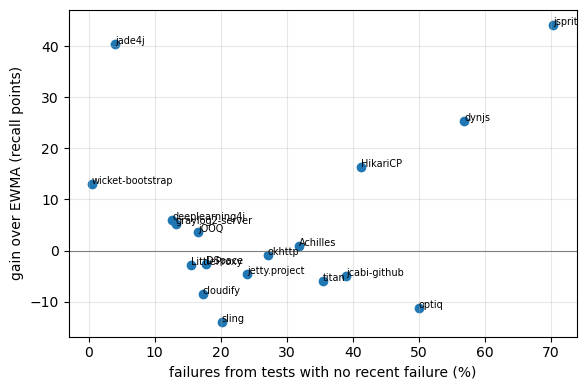

In [15]:
# STEP 13 (E11) — Uses the objects from Step 12 (run Step 12 first, same kernel).
# (a) How good is the exponent rule on ALL projects? Regret = recall lost against each project's best alpha.
# (b) WHEN does the transferred model beat recency? Correlate the per-project gain over EWMA with project
#     traits (failure prevalence, history length, share of failures from tests with no (recent) failure
#     history, suite size). The direction is an empirical question: report whatever comes out.
grid_x = curves_x.columns.to_numpy(float)
near = lambda a: grid_x[np.argmin(np.abs(grid_x - a))]
best = curves_x.max(axis=1)
reg = pd.DataFrame({
    "alpha_theory": fits_x["alpha_theory"], "alpha_LOTO": fits_x["alpha_LOTO"], "alpha_best": fits_x["alpha_best"],
    "recall@best": best,
    "regret theory": [best[p] - curves_x.loc[p, near(fits_x.loc[p, "alpha_theory"])] for p in curves_x.index],
    "regret LOTO": [best[p] - curves_x.loc[p, near(fits_x.loc[p, "alpha_LOTO"])] for p in curves_x.index],
    "regret 0.2": best - curves_x[near(0.2)], "regret 1 (p/d shape)": best - curves_x[near(1.0)],
    "regret 0 (prob. only)": best - curves_x[near(0.0)]})
print("(a) Mean regret over", len(reg), "projects (recall points, mean of 4 budgets):")
display(reg.filter(like="regret").agg(["mean", "median", "max"]).round(2))
display(reg.round(3))

f = X.frame
fail = f[f["failure"] == 1]
traits = pd.DataFrame({
    "failure_cycles": pd.Series(X.cyc_project).value_counts(),
    "prevalence_%": f.groupby("project")["failure"].mean() * 100,
    "first_time_failures_%": (fail["historical_failure_count"] == 0).groupby(fail["project"]).mean() * 100,
    "no_recent_failure_%": (fail["ewma"] < 0.01).groupby(fail["project"]).mean() * 100,
    "median_history_runs": f.groupby("project")["historical_execution_count"].median(),
    "median_tests_per_cycle": pd.Series(X.size).groupby(X.cyc_project).median(),
})
prop = "Proposed: odds * d^-alpha_LOTO"
for base in ["EWMA", "EWMA * d^-0.25", "EnsembleRisk"]:
    traits[f"gain vs {base}"] = (X.by_project(R10[prop]).mean(axis=1) - X.by_project(R10[base]).mean(axis=1)) * 100
traits = traits.sort_values("gain vs EWMA", ascending=False)
print("\n(b) Per-project gain of the proposed score (recall points, mean of 4 budgets) and project traits:")
display(traits.round(2))
rows = []
for g in [c for c in traits.columns if c.startswith("gain")]:
    for t in ["prevalence_%", "first_time_failures_%", "no_recent_failure_%", "median_history_runs", "median_tests_per_cycle"]:
        rho, pv = spearmanr(traits[g], traits[t])
        rows.append({"gain": g, "trait": t, "spearman": rho, "p": pv})
corr = pd.DataFrame(rows); corr["p_holm"] = holm(corr["p"].to_numpy())
display(corr.round(3))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(traits["no_recent_failure_%"], traits["gain vs EWMA"])
for pr, r in traits.iterrows():
    ax.annotate(pr.split("@")[-1], (r["no_recent_failure_%"], r["gain vs EWMA"]), fontsize=7)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("failures from tests with no recent failure (%)"); ax.set_ylabel("gain over EWMA (recall points)")
ax.grid(alpha=0.3); fig.tight_layout(); fig.savefig(OUT / "E11_when_transfer_helps.png", dpi=200); plt.show()
reg.to_csv(OUT / "E11_regret_all_projects.csv"); traits.to_csv(OUT / "E11_project_traits.csv"); corr.to_csv(OUT / "E11_trait_correlations.csv", index=False)


In [16]:
# STEP 14 (E12) — Can a neural network beat the baselines?
# Paste this as ONE new cell at the end of ZST_experiments_v2.ipynb. It needs Steps 0, 1 and 2 in the same
# kernel (it uses `train`, `scored`, the core functions and the settings); it does not depend on Steps 3-13.
#
# Fair test: same five rank features, same transfer protocol (train on ABB only, score RTPTorrent with
# build-level history), same duration rule (alpha = (1 - kappa)/b estimated on the OTHER projects' selection
# cycles), same corrected evaluation (realised budgets, random ties, equal project weight, confirmatory cycles).
# Network settings are chosen on ABB only (chronological 80/20 split per project): no target data is used.
# MLPClassifier in scikit-learn 1.4 has no sample weights, so the network is trained without class weighting;
# Step 8 showed class weighting does not change the result after the duration rule.
import time
from sklearn.neural_network import MLPClassifier

t0 = time.time()
NN_GRID = [(16,), (32, 16), (64, 32), (64, 32, 16)]
NN_L2 = [1e-4, 1e-3]
NN_SEEDS = [0, 1, 2, 3, 4]

def make_mlp(hidden, l2, seed):
    return make_pipeline(StandardScaler(), MLPClassifier(
        hidden_layer_sizes=hidden, alpha=l2, learning_rate_init=1e-3, batch_size=256, max_iter=300,
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=15, random_state=seed))

# 1. Choose the architecture on ABB only: train on the first 80% of each project's cycles, validate on the rest
parts_tr, parts_va = [], []
for pr, g in train.groupby("project"):
    cyc = np.sort(g["cycle_position"].unique()); cut = cyc[int(len(cyc) * 0.8)]
    parts_tr.append(g[g["cycle_position"] < cut]); parts_va.append(g[g["cycle_position"] >= cut])
src_tr, src_va = pd.concat(parts_tr), pd.concat(parts_va).copy()
src_va["estimated_duration"] = src_va["previous_duration"].fillna(src_tr["previous_duration"].median()).clip(lower=1)
src_va = src_va[src_va.groupby(["project", "cycle_position"])["failure"].transform("max") == 1]
V = CycleSet(src_va)
rows = []
for hidden in NN_GRID:
    for l2 in NN_L2:
        m = make_mlp(hidden, l2, 0).fit(src_tr[FEATURES].to_numpy(float), src_tr["failure"].to_numpy(int))
        pv = m.predict_proba(V.frame[FEATURES].to_numpy(float))[:, 1]
        rows.append({"hidden": str(hidden), "l2": l2, "source within-cycle AUC": np.nanmean(V.within_cycle_auc(pv)),
                     "epochs": m[-1].n_iter_})
nn_sel = pd.DataFrame(rows).sort_values("source within-cycle AUC", ascending=False)
display(nn_sel.round(4))
best = nn_sel.iloc[0]
best_hidden, best_l2 = eval(best["hidden"]), float(best["l2"])
print(f"Chosen on ABB only: hidden={best_hidden}, L2={best_l2} ({time.time() - t0:.0f}s)")

# 2. Train on all ABB rows with 5 seeds; score the selection and confirmatory cycles (build-level history)
X_src, y_src = train[FEATURES].to_numpy(float), train["failure"].to_numpy(int)
nets = [make_mlp(best_hidden, best_l2, s).fit(X_src, y_src) for s in NN_SEEDS]
S = CycleSet(scored["build"][scored["build"]["set_selection"]])
C = CycleSet(scored["build"][scored["build"]["set_confirm"]])
pS = np.column_stack([n.predict_proba(S.frame[FEATURES].to_numpy(float))[:, 1] for n in nets])
pC = np.column_stack([n.predict_proba(C.frame[FEATURES].to_numpy(float))[:, 1] for n in nets])
print(f"Networks trained and scored ({time.time() - t0:.0f}s)")

# 3. Duration exponent from the OTHER projects (leave-one-target-out), for any probability column
def loto_alpha(p_sel):
    xs = logit(np.clip(p_sel, EPS, 1 - EPS)); out = {}
    for pr in np.unique(C.cyc_project):
        b, k = S.conditional_slope(xs, mask_cycles=np.flatnonzero(S.cyc_project != pr))
        out[pr] = float(np.clip((1 - k) / b, 0, 1))
    return np.array([out[pr] for pr in C.frame["project"]]), out

def rule(p, a):
    p = np.clip(p, EPS, 1 - EPS)
    return p / (1 - p) * C.est ** -a

# 4. Strategies (all on the same confirmatory cycles)
p_nn = pC.mean(axis=1)                                        # seed-averaged network
a_nn, a_nn_map = loto_alpha(pS.mean(axis=1))
a_ens, _ = loto_alpha(S.frame["p_ens"].to_numpy())
ew = C.frame["ewma"].to_numpy()
strats = {
    "Neural net: probability only": p_nn,
    "Neural net: p/d (full division)": np.clip(p_nn, EPS, 1) / C.est,
    "Neural net: odds * d^-alpha_LOTO": rule(p_nn, a_nn),
    "Ensemble: odds * d^-alpha_LOTO (Step 6)": rule(C.frame["p_ens"].to_numpy(), a_ens),
    "EWMA (baseline)": ew,
    "EWMA * d^-0.25 (baseline)": (ew + 1e-3) * C.est ** -0.25,
}
R = {k: C.recall(v, seeds=TIE_SEEDS) for k, v in strats.items()}
tab = pd.DataFrame({k: equal_weight(C, v) for k, v in R.items()}).T
tab.columns = ["10%", "20%", "30%", "50%"]; tab["mean"] = tab.mean(axis=1)
tab["within-cycle AUC"] = [np.nanmean(C.by_project(C.within_cycle_auc(v)).iloc[:, 0]) if "only" in k or "EWMA (" in k else np.nan
                           for k, v in strats.items()]
print("\nRecall (%), equal project weight, confirmatory cycles:")
display(tab.round(3))
print("Network alpha per project (from the other projects):", {k.split("@")[-1]: round(v, 3) for k, v in a_nn_map.items()})

# 5. Seed stability of the network
seed_rows = []
for j, s in enumerate(NN_SEEDS):
    a_s, _ = loto_alpha(pS[:, j])
    seed_rows.append({"seed": s, "mean recall": equal_weight(C, C.recall(rule(pC[:, j], a_s), seeds=3)).mean(),
                      "within-cycle AUC": np.nanmean(C.by_project(C.within_cycle_auc(pC[:, j])).iloc[:, 0])})
seeds_tab = pd.DataFrame(seed_rows)
display(seeds_tab.round(3))
print(f"Across seeds: mean recall {seeds_tab['mean recall'].mean():.2f} +/- {seeds_tab['mean recall'].std():.2f}")

# 6. Does the network beat the baselines? Equal-weight difference with a hierarchical bootstrap 95% CI
nn_key = "Neural net: odds * d^-alpha_LOTO"
rows = []
for base in ["EWMA * d^-0.25 (baseline)", "EWMA (baseline)", "Ensemble: odds * d^-alpha_LOTO (Step 6)"]:
    for j, bud in enumerate(BUDGETS):
        d = (R[nn_key][:, j] - R[base][:, j]) * 100
        point, lo, hi = hierarchical_bootstrap(d, C.cyc_project, n_boot=2000)
        better = int((C.by_project(R[nn_key][:, j]).iloc[:, 0] > C.by_project(R[base][:, j]).iloc[:, 0]).sum())
        rows.append({"network vs": base, "budget": f"{int(bud*100)}%", "diff_pts": point, "ci_low": lo, "ci_high": hi,
                     "projects_better": f"{better}/{len(np.unique(C.cyc_project))}"})
nn_tests = pd.DataFrame(rows)
display(nn_tests.round(2))
per_proj = pd.DataFrame({k: C.by_project(R[k]).mean(axis=1) * 100 for k in [nn_key, "Ensemble: odds * d^-alpha_LOTO (Step 6)", "EWMA * d^-0.25 (baseline)"]})
display(per_proj.round(1))
nn_sel.to_csv(OUT / "E12_nn_selection_on_ABB.csv", index=False); tab.to_csv(OUT / "E12_nn_recall.csv")
seeds_tab.to_csv(OUT / "E12_nn_seeds.csv", index=False); nn_tests.to_csv(OUT / "E12_nn_vs_baselines.csv", index=False)
print(f"Step 14 done in {time.time() - t0:.0f}s")

,hidden,l2,source within-cycle AUC,epochs
1,"(16,)",0.0010,0.8305,35
0,"(16,)",0.0001,0.8304,35
7,"(64, 32, 16)",0.0010,0.8256,46
4,"(64, 32)",0.0001,0.8217,85
3,"(32, 16)",0.0010,0.8200,48
2,"(32, 16)",0.0001,0.8183,48
6,"(64, 32, 16)",0.0001,0.8090,60
5,"(64, 32)",0.0010,0.8063,111


Chosen on ABB only: hidden=(16,), L2=0.001 (42s)
Networks trained and scored (49s)

Recall (%), equal project weight, confirmatory cycles:


,10%,20%,30%,50%,mean,within-cycle AUC
Neural net: probability only,37.059,48.206,58.510,67.053,52.707,0.879
Neural net: p/d (full division),31.039,42.967,52.240,63.377,47.406,NaN
Neural net: odds * d^-alpha_LOTO,43.444,54.041,62.101,70.947,57.633,NaN
Ensemble: odds * d^-alpha_LOTO (Step 6),42.443,54.546,62.410,70.112,57.378,NaN
EWMA (baseline),43.928,56.518,64.939,71.080,59.116,0.924
EWMA * d^-0.25 (baseline),45.844,58.846,67.081,73.478,61.312,NaN


Network alpha per project (from the other projects): {'cloudify': 0.387, 'sling': 0.407, 'deeplearning4j': 0.327, 'jOOQ': 0.38, 'jcabi-github': 0.374, 'okhttp': 0.366}


,seed,mean recall,within-cycle AUC
0,0,57.590,0.880
1,1,57.269,0.877
2,2,56.648,0.873
3,3,57.867,0.887
4,4,57.708,0.870


Across seeds: mean recall 57.42 +/- 0.48


,network vs,budget,diff_pts,ci_low,ci_high,projects_better
0,EWMA * d^-0.25 (baseline),10%,-2.40,-6.12,0.83,2/6
1,EWMA * d^-0.25 (baseline),20%,-4.81,-9.28,-0.33,2/6
2,EWMA * d^-0.25 (baseline),30%,-4.98,-8.93,-1.23,1/6
3,EWMA * d^-0.25 (baseline),50%,-2.53,-6.14,0.54,2/6
4,EWMA (baseline),10%,-0.48,-5.54,4.58,3/6
5,EWMA (baseline),20%,-2.48,-8.53,3.21,2/6
6,EWMA (baseline),30%,-2.84,-9.03,2.69,2/6
7,EWMA (baseline),50%,-0.13,-6.12,4.65,3/6
8,Ensemble: odds * d^-alpha_LOTO (Step 6),10%,1.00,-0.05,2.15,5/6
9,Ensemble: odds * d^-alpha_LOTO (Step 6),20%,-0.50,-2.22,0.85,2/6


,Neural net: odds * d^-alpha_LOTO,Ensemble: odds * d^-alpha_LOTO (Step 6),EWMA * d^-0.25 (baseline)
project,,,
CloudifySource@cloudify,75.3,74.3,83.4
apache@sling,62.0,62.4,70.9
deeplearning4j@deeplearning4j,64.2,63.5,62.1
jOOQ@jOOQ,56.6,56.1,56.1
jcabi@jcabi-github,36.8,38.6,40.4
square@okhttp,50.9,49.4,55.0


Step 14 done in 60s


In [17]:
# STEP 15 (E13) — What do feature engineering and the ensemble contribute? (paper Table V, RQ4)
# Run after Steps 0-2 (needs: abb, models, scored, FEATURES, CycleSet, ...). Six projects, corrected protocol.
#  A. Each ensemble member alone vs the 4-learner soft-voting ensemble (rank features; reuses Step 2 scores).
#  B. Feature representation with GB+RF+kNN: raw values, log + within-cycle z-score, within-cycle ranks,
#     and leave-one-feature-out on the ranks.
# Every variant gets its OWN leave-one-target-out exponent (b, kappa fitted on the other projects' selection
# cycles). Differences: hierarchical bootstrap 95% CI. About 3-5 minutes (no SVM refit).
t0 = time.time()
THREE = ("gradient_boosting", "random_forest", "knn")
RAW = ["raw_failure_rate", "raw_execution_count", "raw_previous_duration", "previous_verdict_filled", "has_failed_before"]
LOGZ = ["z_failure_rate", "z_log_execution_count", "z_log_previous_duration", "previous_verdict_filled", "has_failed_before"]

def add_all_features(t):
    t = add_scale_free_features(t)
    t["raw_failure_rate"] = t["historical_failure_percentage"].fillna(-1.0)
    t["raw_execution_count"] = t["historical_execution_count"].fillna(-1.0)
    t["raw_previous_duration"] = t["previous_duration"].fillna(-1.0)
    keys = [t["project"], t["cycle_position"]]
    for src, name, f in [("historical_failure_percentage", "z_failure_rate", lambda s: s),
                         ("historical_execution_count", "z_log_execution_count", np.log1p),
                         ("previous_duration", "z_log_previous_duration", lambda s: np.log(s.clip(lower=1e-3)))]:
        v = f(t[src].astype(float))
        mu = v.groupby(keys, sort=False).transform("mean")
        sd = v.groupby(keys, sort=False).transform("std").replace(0, np.nan)
        t[name] = ((v - mu) / sd).fillna(0.0)
    return t

train15 = add_all_features(abb)
b15 = scored["build"]
sub15 = add_all_features(b15[b15["set_selection"] | b15["set_confirm"]].copy())

# Out-of-range check: why raw features cannot transfer
oor = []
for f in ["historical_execution_count", "historical_failure_percentage", "previous_duration"]:
    a, r = abb[f].dropna(), sub15[f].dropna()
    oor.append({"feature": f, "source_median": a.median(), "target_median": r.median(),
                "target_above_source_max_%": 100 * (r > a.max()).mean(), "target_below_source_min_%": 100 * (r < a.min()).mean()})
print("RAW FEATURES OUTSIDE THE SOURCE RANGE"); display(pd.DataFrame(oor).round(3))
print(f"ever failed: source {(abb['historical_failure_count'] > 0).mean():.1%} | target {(sub15['historical_failure_count'] > 0).mean():.1%}")

P15 = {}
for m in models:                                   # Step 2 member probabilities (rank features)
    P15[f"member: {m}"] = sub15[f"probability_{m}"].to_numpy()
M15 = pd.DataFrame({m: sub15[f"probability_{m}"].to_numpy() for m in models})
P15["ensemble: all learners (paper)"] = M15.mean(axis=1).to_numpy()
P15["ensemble: GB+RF+kNN"] = M15[list(THREE)].mean(axis=1).to_numpy()
P15["ensemble: GB+RF"] = M15[["gradient_boosting", "random_forest"]].mean(axis=1).to_numpy()
for label, feats in [("features: raw values", RAW), ("features: log + within-cycle z-score", LOGZ)] + \
                    [(f"ranks without {d}", [f for f in FEATURES if f != d]) for d in FEATURES]:
    m15 = fit_transfer_models(train15, features=feats, which=THREE)
    P15[label] = score_models(m15, sub15, features=feats).mean(axis=1).to_numpy()
    print(f"  scored {label} ({time.time() - t0:.0f}s)")
for k, v in P15.items():
    sub15["P::" + k] = v

S15 = CycleSet(sub15[sub15["set_selection"]]); C15 = CycleSet(sub15[sub15["set_confirm"]])
rows, rule15, pp15 = [], {}, {}
for name in P15:
    ps = S15.frame["P::" + name].clip(EPS, 1 - EPS).to_numpy(); pc = C15.frame["P::" + name].clip(EPS, 1 - EPS).to_numpy()
    xs = logit(ps); b_all, k_all = S15.conditional_slope(xs); al = {}
    for pr in np.unique(C15.cyc_project):
        b, k = S15.conditional_slope(xs, mask_cycles=np.flatnonzero(S15.cyc_project != pr))
        al[pr] = float(np.clip((1 - k) / b, 0, 1))
    a = np.array([al[pr] for pr in C15.frame["project"]]); o = pc / (1 - pc)
    r_rule = C15.recall(o * C15.est ** -a, seeds=TIE_SEEDS); rule15[name] = r_rule.mean(axis=1)
    pp15[name] = C15.by_project(r_rule).mean(axis=1) * 100
    rows.append({"variant": name, "within_cycle_auc": float(np.nanmean(C15.by_project(C15.within_cycle_auc(pc)).iloc[:, 0])),
                 "b_selection": b_all, "kappa_selection": k_all, "alpha_LOTO_min": min(al.values()), "alpha_LOTO_max": max(al.values()),
                 "recall_p": float(equal_weight(C15, C15.recall(pc, seeds=TIE_SEEDS)).mean()),
                 "recall_fixed_0.2": float(equal_weight(C15, C15.recall(o * C15.est ** -0.2, seeds=TIE_SEEDS)).mean()),
                 "recall_fixed_1": float(equal_weight(C15, C15.recall(o * C15.est ** -1.0, seeds=TIE_SEEDS)).mean()),
                 **{f"rule_{int(bb*100)}%": v for bb, v in zip(BUDGETS, equal_weight(C15, r_rule))},
                 "recall_rule": float(equal_weight(C15, r_rule).mean())})
E13 = pd.DataFrame(rows).set_index("variant")
print("\nTABLE V SOURCE (rule = odds * d^-alpha_LOTO, mean of 4 budgets, equal project weight)"); display(E13.round(3))

REF, REF3 = "ensemble: all learners (paper)", "ensemble: GB+RF+kNN"
pairs = [(f"member: {m}", REF) for m in models] + [("ensemble: GB+RF", REF)] + \
        [(n, REF3) for n in P15 if n.startswith("features") or n.startswith("ranks without")]
ci = []
for a_, b_ in pairs:
    pt, lo, hi = hierarchical_bootstrap(100 * (rule15[a_] - rule15[b_]), C15.cyc_project)
    ci.append({"variant": a_, "reference": b_, "delta": pt, "ci_low": lo, "ci_high": hi, "excludes_0": (lo > 0) or (hi < 0)})
E13ci = pd.DataFrame(ci)
print("\nDIFFERENCE FROM REFERENCE, 95% hierarchical bootstrap CI"); display(E13ci.round(2))
E13pp = pd.DataFrame(pp15)
print("\nPER-PROJECT RULE RECALL (%)"); display(E13pp.round(2))
E13.to_csv(OUT / "E13_ensemble_and_features.csv"); E13ci.to_csv(OUT / "E13_differences_ci.csv", index=False)
E13pp.to_csv(OUT / "E13_per_project_rule_recall.csv")
print(f"Step 15 done in {time.time() - t0:.0f}s")


RAW FEATURES OUTSIDE THE SOURCE RANGE


,feature,source_median,target_median,target_above_source_max_%,target_below_source_min_%
0,historical_execution_count,18.00,1769.000,83.057,0.000
1,historical_failure_percentage,0.16,0.000,0.000,0.000
2,previous_duration,54697.00,0.147,0.000,99.985


ever failed: source 79.3% | target 32.8%
  scored features: raw values (4s)
  scored features: log + within-cycle z-score (11s)
  scored ranks without rank_failure_rate (15s)
  scored ranks without rank_execution_count (21s)
  scored ranks without rank_previous_duration (25s)
  scored ranks without previous_verdict_filled (30s)
  scored ranks without has_failed_before (36s)

TABLE V SOURCE (rule = odds * d^-alpha_LOTO, mean of 4 budgets, equal project weight)


,within_cycle_auc,b_selection,kappa_selection,alpha_LOTO_min,alpha_LOTO_max,recall_p,recall_fixed_0.2,recall_fixed_1,rule_10%,rule_20%,rule_30%,rule_50%,recall_rule
variant,,,,,,,,,,,,,
member: gradient_boosting,0.890,1.822,0.316,0.328,0.413,54.202,57.730,53.033,43.123,54.446,62.759,70.822,57.787
member: random_forest,0.884,1.587,0.289,0.396,0.471,52.161,54.905,53.357,41.530,54.028,62.201,69.630,56.847
member: knn,0.841,0.864,0.401,0.532,0.835,50.619,53.306,51.777,37.074,50.854,59.124,66.724,53.444
member: svm,0.859,2.367,0.358,0.233,0.302,52.806,55.925,48.739,41.080,53.376,60.878,68.028,55.840
ensemble: all learners (paper),0.884,2.133,0.293,0.292,0.359,52.195,56.636,51.340,42.443,54.546,62.410,70.112,57.378
ensemble: GB+RF+kNN,0.884,1.814,0.296,0.340,0.420,52.176,55.626,52.847,42.423,54.514,62.252,70.125,57.329
ensemble: GB+RF,0.896,1.790,0.293,0.349,0.423,53.245,57.108,53.181,42.727,54.374,63.068,70.787,57.739
features: raw values,0.645,1.926,0.511,0.209,0.323,41.621,42.800,40.300,27.968,37.323,47.492,56.982,42.441
features: log + within-cycle z-score,0.891,1.641,0.284,0.395,0.467,53.905,57.699,55.172,42.789,54.602,64.096,72.690,58.544



DIFFERENCE FROM REFERENCE, 95% hierarchical bootstrap CI


,variant,reference,delta,ci_low,ci_high,excludes_0
0,member: gradient_boosting,ensemble: all learners (paper),0.41,-1.08,1.75,False
1,member: random_forest,ensemble: all learners (paper),-0.53,-1.31,0.19,False
2,member: knn,ensemble: all learners (paper),-3.93,-6.07,-2.05,True
3,member: svm,ensemble: all learners (paper),-1.54,-3.01,-0.25,True
4,ensemble: GB+RF,ensemble: all learners (paper),0.36,-0.32,0.98,False
5,features: raw values,ensemble: GB+RF+kNN,-14.89,-26.56,-5.32,True
6,features: log + within-cycle z-score,ensemble: GB+RF+kNN,1.22,-0.97,3.40,False
7,ranks without rank_failure_rate,ensemble: GB+RF+kNN,-2.66,-4.25,-1.25,True
8,ranks without rank_execution_count,ensemble: GB+RF+kNN,1.16,0.05,2.36,True
9,ranks without rank_previous_duration,ensemble: GB+RF+kNN,-1.13,-2.24,0.14,False



PER-PROJECT RULE RECALL (%)


,member: gradient_boosting,member: random_forest,member: knn,member: svm,ensemble: all learners (paper),ensemble: GB+RF+kNN,ensemble: GB+RF,features: raw values,features: log + within-cycle z-score,ranks without rank_failure_rate,ranks without rank_execution_count,ranks without rank_previous_duration,ranks without previous_verdict_filled,ranks without has_failed_before
project,,,,,,,,,,,,,,
CloudifySource@cloudify,75.11,73.45,65.85,73.20,74.27,74.24,74.67,33.66,77.22,73.74,76.53,71.81,49.47,74.90
apache@sling,59.80,63.01,57.26,58.86,62.37,62.09,62.43,39.40,66.54,58.75,64.62,59.44,50.72,60.72
deeplearning4j@deeplearning4j,63.85,62.75,61.57,63.62,63.48,63.46,64.85,61.48,62.57,61.33,63.11,63.18,61.34,63.42
jOOQ@jOOQ,56.22,55.83,52.02,56.17,56.11,56.22,56.39,52.22,54.70,54.02,56.06,55.33,51.61,56.39
jcabi@jcabi-github,39.51,37.14,37.09,36.60,38.59,38.58,38.14,33.84,37.34,36.41,40.44,39.05,38.77,36.99
square@okhttp,52.23,48.90,46.88,46.60,49.44,49.37,49.96,34.05,52.89,43.76,50.18,48.40,47.66,48.84


Step 15 done in 78s


In [18]:
# STEP 16 (E14) — Two checks for the paper: random tie-breaking and the exponent-only ablation.
# Paste as ONE new cell at the end of the notebook. Needs Steps 0, 1 and 2 in the same kernel (it uses
# `scored`, CycleSet, paired, holm, equal_weight, cycle_weight, hierarchical_bootstrap and the settings);
# it does not depend on Steps 3-15.
#
# E14a  Random tie-breaking. The paper breaks ties by test id. Every strategy of Table VI is re-run with ties
#       broken at random (TIE_SEEDS seeds; every strategy gets the same random keys, so paired comparisons are
#       fair), and Table X (hybrid minus each baseline, Holm over 12 tests) is recomputed under random ties.
# E14b  Exponent-only ablation p * d^-alpha (no prevalence shift). alpha is chosen on the SELECTION cycles the
#       same way the paper chose 0.2 for the hybrid (best mean recall over the four budgets), then evaluated on
#       the CONFIRMATORY cycles against the hybrid p~ * d^-0.2.
# Both run under two protocols:
#   "paper"     = job-level history, budgets in estimated durations, cycle-weighted means. This reproduces the
#                 numbers now in the paper; the cell checks that first against Tables VI and XII and Fig. 2.
#   "corrected" = build-level history, budgets in realised durations, equal project weight (Step 3).
# Outputs: tables below, LaTeX rows for the paper, OUT/E14_*.csv and OUT/E14_summary.json.
import json
t0 = time.time()
SWEEP_SEEDS = 5                                   # random-tie seeds for the alpha sweep (Step 5 also uses 5)
ALPHA_GRID = np.round(np.arange(0, 1.0001, 0.1), 1)
BCOLS = [f"{int(round(b * 100))}%" for b in BUDGETS]
HYB = f"Hybrid p~*d^-{HYBRID_ALPHA_PAPER}"
PROTOCOLS = {"paper":     dict(level="job",   cost="est", weight="cycle"),
             "corrected": dict(level="build", cost="obs", weight="equal")}

# Numbers currently in the paper (cycle-weighted, id ties): Table VI recall, Table XII APFD/APFDc, Fig. 2 curves.
PAPER_TAB6 = {
    "selection": {"Hybrid": [45.93, 57.68, 66.60, 75.52], "RiskPerTime (prior)": [40.34, 54.55, 60.35, 71.93],
                  "RiskPerTime (raw)": [30.55, 47.54, 54.58, 66.09], "EnsembleRisk": [42.01, 54.94, 63.87, 70.48],
                  "HistoricalFailure": [34.57, 49.47, 61.41, 69.42], "ShortestFirst": [22.89, 31.86, 43.63, 55.69]},
    "confirmatory": {"Hybrid": [38.56, 54.48, 64.88, 75.66], "RiskPerTime (prior)": [34.77, 50.68, 56.46, 71.06],
                     "RiskPerTime (raw)": [27.78, 42.91, 50.13, 64.40], "EnsembleRisk": [35.45, 50.15, 61.16, 69.52],
                     "HistoricalFailure": [29.84, 45.86, 61.39, 70.90], "ShortestFirst": [21.49, 30.24, 39.61, 51.44]}}
PAPER_TAB12 = {"Hybrid": (70.57, 79.12), "RiskPerTime (prior)": (32.61, 73.59), "EnsembleRisk": (87.08, 75.32),
               "HistoricalFailure": (89.11, 75.60), "ShortestFirst": (18.15, 57.35)}
PAPER_FIG2 = {"selection":    [57.82, 60.52, 61.43, 61.25, 61.15, 60.76, 60.15, 59.16, 58.06, 57.37, 56.79],
              "confirmatory": [54.07, 56.62, 58.40, 58.52, 58.42, 57.85, 57.15, 56.07, 54.82, 53.83, 53.25]}

def summarise(C, per_cycle, weight):
    v = cycle_weight(per_cycle) if weight == "cycle" else equal_weight(C, per_cycle)
    return np.atleast_1d(np.asarray(v, float))

def base_scores(C):
    p = C.frame["p_ens"].clip(EPS, 1 - EPS).to_numpy()
    return p, C.per_cycle_shift(p, C.paper_prior_target())

def table6_strategies(C):
    p, pt = base_scores(C)
    return {"Hybrid": pt * C.est ** -HYBRID_ALPHA_PAPER, "RiskPerTime (prior)": pt / C.est,
            "RiskPerTime (raw)": p / C.est, "EnsembleRisk": p,
            "HistoricalFailure": C.frame["historical_failure_percentage"].fillna(0).to_numpy(),
            "ShortestFirst": -C.est}

def test_family(target, baselines, cols=BCOLS):
    """Paired Wilcoxon (zeros dropped) of target minus each baseline per budget; Holm over the whole family.
    diff_pts is the cycle-weighted mean of per-cycle differences, as in Table X."""
    rows = []
    for bname, b in baselines.items():
        for j, col in enumerate(cols):
            st = paired(target[:, j], b[:, j])
            rows.append({"baseline": bname, "budget": col, "diff_pts": 100 * st["mean_diff"],
                         "improved": st["improved"], "worse": st["worse"], "p": st["p"], "rank_biserial": st["rb"]})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p"].to_numpy())
    out["sig"] = out["p_holm"] < 0.05
    return out

def star(d, sig):
    return f"{d:+.2f}" + ("*" if sig else "")

summary = {}
for proto, cfg in PROTOCOLS.items():
    frame = scored[cfg["level"]]
    sets = {"selection": CycleSet(frame[frame["set_selection"]]), "confirmatory": CycleSet(frame[frame["set_confirm"]])}
    Ccon, W, cost = sets["confirmatory"], cfg["weight"], cfg["cost"]
    print(f"\n{'=' * 30} protocol: {proto}  {cfg} {'=' * 30}")
    print(f"selection cycles {sets['selection'].n_cyc:,} | confirmatory cycles {Ccon.n_cyc:,}")

    # ------------------------------------------------------------------------------------------------
    # E14a  Random tie-breaking
    # ------------------------------------------------------------------------------------------------
    rec, rows = {}, []
    for set_name, C_ in sets.items():
        for name, s in table6_strategies(C_).items():
            for tie in ["id", "random"]:
                r = C_.recall(s, cost=cost, seeds=TIE_SEEDS, tie=tie)
                rec[(set_name, name, tie)] = r
                row = {"set": set_name, "strategy": name, "ties": tie, **dict(zip(BCOLS, summarise(C_, r, W)))}
                if set_name == "confirmatory":
                    apfd, apfdc = C_.order_metrics(s, seeds=TIE_SEEDS, tie=tie)
                    row["APFD"] = summarise(C_, apfd, W)[0]        # summarise() returns percent
                    row["APFDc"] = summarise(C_, apfdc, W)[0]
                rows.append(row)
    E14a = pd.DataFrame(rows)
    conf = E14a[E14a["set"] == "confirmatory"].set_index(["strategy", "ties"])
    tie_tab = pd.concat({"id ties": conf.xs("id", level="ties")[BCOLS + ["APFD", "APFDc"]],
                         "random ties": conf.xs("random", level="ties")[BCOLS + ["APFD", "APFDc"]]}, axis=1)
    delta = conf.xs("random", level="ties")[BCOLS + ["APFD", "APFDc"]] - conf.xs("id", level="ties")[BCOLS + ["APFD", "APFDc"]]
    print(f"\nE14a  Confirmatory cycles, {'cycle-weighted' if W == 'cycle' else 'equal project weight'} (%):")
    display(tie_tab.round(2))
    print("Random minus id ties (points):")
    display(delta.round(2))
    print(f"Largest change from random tie-breaking: {delta[BCOLS].abs().to_numpy().max():.2f} recall points, "
          f"{delta[['APFD', 'APFDc']].abs().to_numpy().max():.2f} APFD/APFDc points")

    if proto == "paper":   # does the 'paper' protocol reproduce the paper? (id ties, cycle-weighted)
        chk = []
        for set_name in ["selection", "confirmatory"]:
            for name, ref in PAPER_TAB6[set_name].items():
                ours = E14a[(E14a["set"] == set_name) & (E14a["strategy"] == name) & (E14a["ties"] == "id")][BCOLS].to_numpy()[0]
                chk.append({"set": set_name, "strategy": name, "max_abs_diff_recall": float(np.abs(ours - ref).max())})
        for name, (apfd_ref, apfdc_ref) in PAPER_TAB12.items():
            r = conf.loc[(name, "id")]
            chk.append({"set": "confirmatory", "strategy": name + " (APFD | APFDc)",
                        "max_abs_diff_recall": np.nan, "APFD_diff": r["APFD"] - apfd_ref, "APFDc_diff": r["APFDc"] - apfdc_ref})
        print("\nSanity check against the paper (should be ~0; APFDc here uses realised durations):")
        display(pd.DataFrame(chk).round(3))

    R_rnd = {name: rec[("confirmatory", name, "random")] for name in table6_strategies(Ccon)}
    tests_a = test_family(R_rnd["Hybrid"], {b: R_rnd[b] for b in ["EnsembleRisk", "RiskPerTime (prior)", "HistoricalFailure"]})
    print("\nTable X under RANDOM ties (hybrid minus baseline, Holm over 12):")
    display(tests_a.round(4))
    apfd_h, apfdc_h = Ccon.order_metrics(table6_strategies(Ccon)["Hybrid"], seeds=TIE_SEEDS, tie="random")
    rows = []
    for b in ["EnsembleRisk", "HistoricalFailure"]:
        apfd_b, apfdc_b = Ccon.order_metrics(table6_strategies(Ccon)[b], seeds=TIE_SEEDS, tie="random")
        st = paired(apfdc_h, apfdc_b)
        rows.append({"baseline": b, "APFDc_diff_pts": 100 * st["mean_diff"], "p": st["p"], "rank_biserial": st["rb"]})
    tests_c = pd.DataFrame(rows); tests_c["p_holm"] = holm(tests_c["p"].to_numpy())
    print("Hybrid APFDc vs EnsembleRisk and HistoricalFailure under random ties (Holm over 2):")
    display(tests_c.round(4))

    # ------------------------------------------------------------------------------------------------
    # E14b  Exponent-only ablation p * d^-alpha
    # ------------------------------------------------------------------------------------------------
    tie_sel = "id" if proto == "paper" else "random"          # paper chose alpha = 0.2 with id ties
    seeds_sel = 1 if tie_sel == "id" else SWEEP_SEEDS
    curve_rows = []
    for set_name, C_ in sets.items():
        p, pt = base_scores(C_)
        for a in ALPHA_GRID:
            for fam, base in [("exponent only p*d^-a", p), ("hybrid p~*d^-a", pt)]:
                r = C_.recall(base * C_.est ** -a, cost=cost, seeds=seeds_sel, tie=tie_sel)
                curve_rows.append({"set": set_name, "score": fam, "alpha": a, "mean_recall": summarise(C_, r, W).mean()})
    curve = pd.DataFrame(curve_rows).pivot_table(index="alpha", columns=["set", "score"], values="mean_recall")
    a_eo = float(curve[("selection", "exponent only p*d^-a")].idxmax())
    a_hy = float(curve[("selection", "hybrid p~*d^-a")].idxmax())
    print(f"\nE14b  Mean recall over the four budgets vs alpha ({tie_sel} ties):")
    display(curve.round(2))
    print(f"alpha chosen on the SELECTION cycles: exponent only = {a_eo}, hybrid = {a_hy} (paper: hybrid 0.2)")
    if proto == "paper":
        dev = {s: float(np.abs(curve[(s, "hybrid p~*d^-a")].to_numpy() - np.array(PAPER_FIG2[s])).max()) for s in PAPER_FIG2}
        print(f"Sanity check vs Fig. 2 (hybrid curve, max abs diff): {dev}")

    p, pt = base_scores(Ccon)
    cand = {HYB: pt * Ccon.est ** -HYBRID_ALPHA_PAPER,
            f"Exponent only p*d^-{a_eo} (alpha from selection)": p * Ccon.est ** -a_eo}
    if a_eo != HYBRID_ALPHA_PAPER:
        cand[f"Exponent only p*d^-{HYBRID_ALPHA_PAPER}"] = p * Ccon.est ** -HYBRID_ALPHA_PAPER
    cand.update({"RiskPerTime (prior) p~/d": pt / Ccon.est, "EnsembleRisk p": p})
    eo_names = [k for k in cand if k.startswith("Exponent only")]
    E14b, tests_b = {}, {}
    for tie in (["id", "random"] if proto == "paper" else ["random"]):
        R = {k: Ccon.recall(v, cost=cost, seeds=TIE_SEEDS, tie=tie) for k, v in cand.items()}
        rows = []
        for k, r in R.items():
            apfd, apfdc = Ccon.order_metrics(cand[k], seeds=TIE_SEEDS, tie=tie)
            rows.append({"score": k, **dict(zip(BCOLS, summarise(Ccon, r, W))), "mean": summarise(Ccon, r, W).mean(),
                         "APFD": summarise(Ccon, apfd, W)[0], "APFDc": summarise(Ccon, apfdc, W)[0]})
        E14b[tie] = pd.DataFrame(rows).set_index("score")
        tests_b[tie] = test_family(R[HYB], {k: R[k] for k in eo_names})
        print(f"\nConfirmatory cycles, {tie} ties, {'cycle-weighted' if W == 'cycle' else 'equal project weight'} (%):")
        display(E14b[tie].round(2))
        print(f"Hybrid minus exponent-only ({tie} ties, Holm over {len(tests_b[tie])}):")
        display(tests_b[tie].round(4))
        if tie == "random":
            ci_rows = []
            for k in eo_names:
                for j, col in enumerate(BCOLS):
                    pt_, lo, hi = hierarchical_bootstrap(100 * (R[HYB][:, j] - R[k][:, j]), Ccon.cyc_project, n_boot=1000)
                    ci_rows.append({"contrast": f"Hybrid - {k}", "budget": col, "eq_weight_diff": pt_, "ci_low": lo, "ci_high": hi})
            ci_tab = pd.DataFrame(ci_rows)
            print("Equal-project-weight difference, 95% hierarchical bootstrap CI:")
            display(ci_tab.round(2))
            per_proj = pd.DataFrame({k: Ccon.by_project(R[k]).iloc[:, 2] * 100 for k in [HYB] + eo_names})
            print("Recall at the 30% budget per project (%):")
            display(per_proj.round(1))

    # Selection-set row for the exponent-only score (for Table VI, paper protocol, id ties)
    Csel = sets["selection"]; ps, _ = base_scores(Csel)
    eo_sel = summarise(Csel, Csel.recall(ps * Csel.est ** -a_eo, cost=cost, seeds=seeds_sel, tie=tie_sel), W)

    # ------------------------------------------------------------------------------------------------
    # Save, and print LaTeX rows (paper protocol = the numbers that go into the current paper)
    # ------------------------------------------------------------------------------------------------
    tag = f"E14_{proto}"
    E14a.to_csv(OUT / f"{tag}_ties.csv", index=False); tests_a.to_csv(OUT / f"{tag}_tableX_random_ties.csv", index=False)
    curve.to_csv(OUT / f"{tag}_alpha_curves.csv")
    for tie, t in E14b.items():
        t.to_csv(OUT / f"{tag}_exponent_only_{tie}.csv"); tests_b[tie].to_csv(OUT / f"{tag}_exponent_only_tests_{tie}.csv", index=False)
    summary[proto] = {"protocol": cfg, "max_recall_change_random_vs_id": float(delta[BCOLS].abs().to_numpy().max()),
                      "tie_table": tie_tab.round(2).set_axis([f"{a} {b}" for a, b in tie_tab.columns], axis=1)
                                          .reset_index().to_dict(orient="records"),
                      "tableX_random_ties": tests_a.round(5).to_dict(orient="records"),
                      "apfdc_tests_random_ties": tests_c.round(5).to_dict(orient="records"),
                      "alpha_exponent_only": a_eo, "alpha_hybrid_reselected": a_hy,
                      "exponent_only_selection_recall": [round(float(v), 2) for v in eo_sel],
                      "exponent_only_confirmatory": {t: v.round(2).reset_index().to_dict(orient="records") for t, v in E14b.items()},
                      "exponent_only_tests": {t: v.round(5).to_dict(orient="records") for t, v in tests_b.items()}}

    if proto == "paper":
        print("\n% ---------- LaTeX rows (paper protocol, cycle-weighted) ----------")
        print("% New table: recall (%) under id vs random tie-breaking, confirmatory set")
        print("% Strategy & id 10 & 20 & 30 & 50 & random 10 & 20 & 30 & 50 \\\\")
        for name in table6_strategies(Ccon):
            vals = list(tie_tab.loc[name, "id ties"][BCOLS]) + list(tie_tab.loc[name, "random ties"][BCOLS])
            print(f"{name} & " + " & ".join(f"{v:.2f}" for v in vals) + r" \\")
        print("\n% Table X under random ties (hybrid minus baseline; * Holm-significant over 12)")
        for b in ["EnsembleRisk", "RiskPerTime (prior)", "HistoricalFailure"]:
            sub = tests_a[tests_a["baseline"] == b].set_index("budget").loc[BCOLS]
            print(f"{b} & " + " & ".join(star(r.diff_pts, r.sig) for r in sub.itertuples()) + r" \\")
        print("\n% Extra row for Table VI (selection | confirmatory recall, id ties)")
        eo_conf = E14b["id"].loc[[k for k in eo_names if "from selection" in k][0], BCOLS]
        print(f"Exponent only ($\\alpha={a_eo}$) & " + " & ".join(f"{v:.2f}" for v in list(eo_sel) + list(eo_conf)) + r" \\")
        print("\n% Hybrid minus exponent-only (confirmatory, id ties; * Holm-significant)")
        for k in eo_names:
            sub = tests_b["id"][tests_b["id"]["baseline"] == k].set_index("budget").loc[BCOLS]
            print(f"{k} & " + " & ".join(star(r.diff_pts, r.sig) for r in sub.itertuples()) + r" \\")

with open(OUT / "E14_summary.json", "w") as fh:
    json.dump(summary, fh, indent=1, default=float)
print(f"\nSaved OUT/E14_*.csv and OUT/E14_summary.json  ({time.time() - t0:.0f}s)")


============================== protocol: paper  {'level': 'job', 'cost': 'est', 'weight': 'cycle'} ==============================
selection cycles 1,800 | confirmatory cycles 2,111

E14a  Confirmatory cycles, cycle-weighted (%):


id ties                                    random ties  \
                        10%    20%    30%    50%   APFD  APFDc         10%   
strategy                                                                     
Hybrid                38.56  54.48  64.88  75.66  70.57  79.12       38.58   
RiskPerTime (prior)   34.77  50.68  56.46  71.06  32.61  73.59       34.79   
RiskPerTime (raw)     27.78  42.91  50.13  64.40  25.28  67.04       27.78   
EnsembleRisk          35.45  50.15  61.16  69.52  87.08  75.32       35.46   
HistoricalFailure     29.84  45.86  61.39  70.90  89.11  75.60       29.69   
ShortestFirst         21.49  30.24  39.61  51.44  18.15  57.35       21.49   

                                                        
                       20%    30%    50%   APFD  APFDc  
strategy                                                
Hybrid               54.46  64.82  75.65  70.56  79.15  
RiskPerTime (prior)  50.67  56.41  71.05  32.60  73.62  
RiskPerTime (raw)    42.89  50.07  64.37  25.27  67.07  
EnsembleRisk         50.13  61.10  69.51  87.07  75.35  
HistoricalFailure    45.68  61.28  70.99  89.07  75.72  
ShortestFirst        30.21  39.56  51.42  18.14  57.38

Random minus id ties (points):


,10%,20%,30%,50%,APFD,APFDc
strategy,,,,,,
Hybrid,0.01,-0.01,-0.06,-0.01,-0.01,0.03
RiskPerTime (prior),0.01,-0.01,-0.06,-0.01,-0.01,0.03
RiskPerTime (raw),0.00,-0.01,-0.06,-0.03,-0.01,0.03
EnsembleRisk,0.01,-0.01,-0.06,-0.01,-0.01,0.03
HistoricalFailure,-0.15,-0.17,-0.10,0.09,-0.04,0.12
ShortestFirst,0.00,-0.02,-0.06,-0.03,-0.01,0.03


Largest change from random tie-breaking: 0.17 recall points, 0.12 APFD/APFDc points

Sanity check against the paper (should be ~0; APFDc here uses realised durations):


...

Equal-project-weight difference, 95% hierarchical bootstrap CI:


,contrast,budget,eq_weight_diff,ci_low,ci_high
0,Hybrid - Exponent only p*d^-0.2 (alpha from se...,10%,-0.09,-1.59,1.54
1,Hybrid - Exponent only p*d^-0.2 (alpha from se...,20%,-1.44,-3.17,-0.28
2,Hybrid - Exponent only p*d^-0.2 (alpha from se...,30%,-0.31,-1.22,0.58
3,Hybrid - Exponent only p*d^-0.2 (alpha from se...,50%,0.04,-0.62,0.67


Recall at the 30% budget per project (%):


,Hybrid p~*d^-0.2,Exponent only p*d^-0.2 (alpha from selection)
project,,
CloudifySource@cloudify,81.4,80.2
apache@sling,65.6,66.5
deeplearning4j@deeplearning4j,74.2,74.2
jOOQ@jOOQ,55.6,57.3
jcabi@jcabi-github,39.4,39.4
square@okhttp,54.4,54.8



Saved OUT/E14_*.csv and OUT/E14_summary.json  (46s)
